# PRAICP-1000: Indian Sign Language (ISL) Recognition
### Advanced end-to-end deep learning project

## 1. Business Case
Communication barriers limit the daily life of the deaf and hard-of-hearing community in India. This project builds a Machine Learning system that recognises Indian Sign Language signs from images, a first step towards accessible, real-time sign-to-text tools.

## 2. Project Goals (from the brief)
1. **Image preprocessing**: clean, audit, standardise and augment the sign images.
2. **ML model** to predict the sign.

## 3. What makes this notebook "production-minded"
| Area | Technique |
|---|---|
| Data integrity | Corrupt-file check, exact and near-duplicate detection, **leakage-safe grouped split** |
| Data understanding | Class balance, image quality (blur, brightness, contrast), mean images |
| Preprocessing | OpenCV pipeline demo, `tf.data` pipeline, class-weighted training, safe augmentation (no flips) |
| Modelling | Baseline CNN, **MobileNetV2** and **EfficientNetB0** transfer learning with 2-stage fine-tuning, label smoothing, AdamW |
| Ensembling | Probability-averaging ensemble |
| Alternative approach | **MediaPipe hand landmarks** + SVM / Random Forest (background-invariant) |
| Evaluation | Accuracy, top-3, macro-F1, kappa, MCC, confusion matrix, per-class F1, selective prediction |
| Trust | **Calibration** (ECE, temperature scaling), **Grad-CAM** explainability, t-SNE embeddings |
| Robustness | Accuracy under darkness, brightness, noise, blur, rotation and occlusion, **used to choose the deployed model**, plus a test on your own photos |
| Deployment | Saved model, **TFLite (quantised)** export with latency benchmark, TTA inference helper, webcam demo, Gradio app, model card |

## Table of contents
1. Setup and configuration
2. Data loading
3. Data audit (corruption, duplicates, quality)
4. Exploratory data analysis
5. Preprocessing and leakage-safe splitting
6. Input pipeline and augmentation
7. Models: baseline CNN, MobileNetV2, EfficientNetB0
8. Evaluation and ensemble
9. Reliability: calibration and selective prediction
10. Explainability: Grad-CAM and embeddings
11. Robustness testing and your own photos
12. Landmark-based approach (MediaPipe)
13. Deployment: export, benchmark, inference, demo
14. Leaderboard, model card and conclusion

## 1. Setup and Configuration

In [1]:
# Mount Google Drive so Colab can read the dataset zip you uploaded there
from google.colab import drive
# A pop-up asks for permission: click Connect / Allow
drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive


In [2]:
# Check that the zip file exists in Drive and is complete (about 80 MB)
import os
# Location of the dataset zip inside Google Drive
zip_path = "/content/drive/MyDrive/IndiSignLang/IndiSignLang.zip"
print("Exists:", os.path.exists(zip_path))
print("Size (MB):", round(os.path.getsize(zip_path) / 1e6, 1))

Exists: True
Size (MB): 84.6


In [3]:
# Unzip the dataset from Drive into Colab's fast local disk (training reads images many times, so local is much faster than Drive)
import zipfile
from pathlib import Path

# Extract every file from the zip into /content/isl_data
with zipfile.ZipFile(zip_path) as z:
    z.extractall("/content/isl_data")

# Show what was extracted
for p in sorted(Path("/content/isl_data").iterdir())[:30]:
    print(p)

/content/isl_data/Data


In [4]:
# ---- Standard library: files, random numbers, hashing, timing, JSON ----
import os, random, zipfile, urllib.request, warnings, hashlib, time, json, platform
from pathlib import Path
from collections import deque

# ---- Data handling, plotting and image libraries ----
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image, ImageOps   # ImageOps.pad keeps the aspect ratio when resizing

# ---- scikit-learn: data splitting, metrics, class weights, t-SNE and classical ML models ----
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_val_score
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score, f1_score,
                             cohen_kappa_score, matthews_corrcoef, top_k_accuracy_score)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.manifold import TSNE
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
# scipy: used later to find the best calibration temperature
from scipy.optimize import minimize_scalar

# ---- TensorFlow / Keras: the deep learning framework ----
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Hide non-critical warnings and use a clean plot style
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
# Fixed random seed so results are reproducible (same split, same shuffling)
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# ---------------- Configuration ----------------
# Put the path to YOUR dataset folder here (the folder that contains one sub-folder per sign)
DATA_DIR = Path("/content/isl_data")    # e.g. Path(r"D:\datasets\IndiSignLang") or Path("/content/drive/MyDrive/IndiSignLang")# only used if you upload a zip instead of a folder
# Folder where models, class names and results are saved
OUT        = Path("artifacts"); OUT.mkdir(exist_ok=True)
# Every image is resized to IMG_SIZE x IMG_SIZE pixels before it enters a model
IMG_SIZE   = 160
# Number of images processed together in one training step
BATCH_SIZE = 32
# File types that are treated as images
IMG_EXT    = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

QUICK_RUN  = False        # True = tiny subset + few epochs, to debug the notebook quickly
# Epochs = full passes over the training data (early stopping may finish sooner)
# BASE = baseline CNN, HEAD = new classifier layer, FT = fine-tuning stage
EPOCHS_BASE, EPOCHS_HEAD, EPOCHS_FT = 20, 8, 12
UNFREEZE_LAYERS = 40      # top backbone layers unfrozen during fine-tuning
# Debug mode: only a couple of epochs so the whole notebook runs in minutes
if QUICK_RUN:
    EPOCHS_BASE, EPOCHS_HEAD, EPOCHS_FT = 2, 1, 1

# Print library versions and whether a GPU is available
print("Python     :", platform.python_version())
print("TensorFlow :", tf.__version__, "| Keras:", keras.__version__)
print("GPU        :", tf.config.list_physical_devices("GPU") or "none (training will be slow, use Colab GPU)")

Python     : 3.13.16
TensorFlow : 2.21.0 | Keras: 3.13.2
GPU        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Data Loading
The zip is downloaded and extracted once (skipped if already present). The folder layout may vary (wrapper folders, `train/test` sub-folders), so we scan for every image and use the **parent folder name as the class label**.

In [5]:
# Load the dataset: find every image and use the name of its parent folder as the sign label
# Stop with a clear message if the dataset folder is missing (run the Drive-mount and unzip cells first)
if not DATA_DIR.exists():
    raise FileNotFoundError(f"{DATA_DIR} not found. Run the cells above first: mount Drive, then unzip the dataset.")

# Scan all sub-folders for image files (ignoring macOS '__MACOSX' junk) and keep (path, label) pairs
records = [(str(p), p.parent.name) for p in DATA_DIR.rglob("*")
           if p.is_file() and p.suffix.lower() in IMG_EXT and "__MACOSX" not in p.parts]
# Table with one row per image
df = pd.DataFrame(records, columns=["path", "label"])

# Debug mode: keep only 60 images per sign
if QUICK_RUN:
    df = df.groupby("label").head(60).reset_index(drop=True)

# Sanity check: number of images and signs (expect the 26 letters A-Z)
print("Total images :", len(df))
print("Total classes:", df["label"].nunique())
print("Classes      :", sorted(df["label"].unique()))
df.head()

Total images : 4972
Total classes: 24
Classes      : ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']


,path,label
0,/content/isl_data/Data/R/089.jpg,R
1,/content/isl_data/Data/R/026.jpg,R
2,/content/isl_data/Data/R/165.jpg,R
3,/content/isl_data/Data/R/219.jpg,R
4,/content/isl_data/Data/R/001.jpg,R


## 3. Data Audit
Before modelling we check three things that silently ruin image projects:

1. **Corrupted files** that crash training.
2. **Exact duplicates** (same bytes) and **near duplicates** (same perceptual hash). If the same photo sits in both train and test, the test score is inflated.
3. **Image quality** (blur, brightness, contrast), to spot unusable samples.

In [6]:
# Data audit helpers: find corrupted files and duplicate images before training
# MD5 fingerprint of the file bytes: identical files give identical hashes (exact duplicates)
def md5_of(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

# Perceptual 'difference hash': a 256-bit fingerprint of how an image looks, so near-identical photos get the same value
def dhash(path, hash_size=16):
    # Difference hash: robust to resizing and small compression changes
    with Image.open(path) as im:
        im = im.convert("L").resize((hash_size + 1, hash_size), Image.LANCZOS)
    a = np.asarray(im, dtype=np.int16)
    return "".join("1" if b else "0" for b in (a[:, 1:] > a[:, :-1]).flatten())

# For one image: check it opens correctly and collect its size, colour mode, MD5 and dhash.
# Returns Nones if the file is corrupted
def audit_row(path):
    try:
        with Image.open(path) as im:
            # verify() raises an error if the file is truncated or damaged
            im.verify()
        with Image.open(path) as im:
            # Re-open the file, because verify() leaves the image object unusable
            w, h = im.size; mode = im.mode
        return w, h, mode, md5_of(path), dhash(path)
    # Any error means the image is unreadable
    except Exception:
        return (None,) * 5

# Run the audit on every image (can take a minute or two)
t0 = time.time()
audit = [audit_row(p) for p in df["path"]]
# Store the audit results as new columns
df[["width", "height", "mode", "md5", "dhash"]] = pd.DataFrame(audit, index=df.index)
print(f"Audit finished in {time.time() - t0:.0f}s")

# Drop corrupted images (they have no hash)
bad = df["md5"].isna().sum()
print("Corrupted / unreadable images:", bad)
df = df.dropna(subset=["md5"]).reset_index(drop=True)

Audit finished in 32s
Corrupted / unreadable images: 0


In [7]:
# ---- Exact duplicates ----
# Count files whose bytes are identical to an earlier file
dup_mask = df.duplicated("md5", keep="first")
print("Exact duplicate files:", int(dup_mask.sum()))

# Same bytes but different labels = label noise. Remove every copy.
conflict_md5 = df.groupby("md5")["label"].nunique()
# Keep only the MD5 values that appear under more than one label
conflict_md5 = conflict_md5[conflict_md5 > 1].index
print("Identical images with conflicting labels:", len(conflict_md5))
# Remove every copy of those conflicting images
df = df[~df["md5"].isin(conflict_md5)]
# Keep only the first copy of each remaining exact duplicate
df = df.drop_duplicates("md5", keep="first").reset_index(drop=True)

# ---- Near duplicates (same perceptual hash) ----
# Count how many images share each perceptual hash (more than 1 means near-duplicates)
grp_sizes = df.groupby("dhash").size()
print("Near-duplicate groups (>1 image):", int((grp_sizes > 1).sum()),
      "| images inside them:", int(grp_sizes[grp_sizes > 1].sum()))
print("Images remaining after cleaning :", len(df))

Exact duplicate files: 1
Identical images with conflicting labels: 0
Near-duplicate groups (>1 image): 16 | images inside them: 38
Images remaining after cleaning : 4971


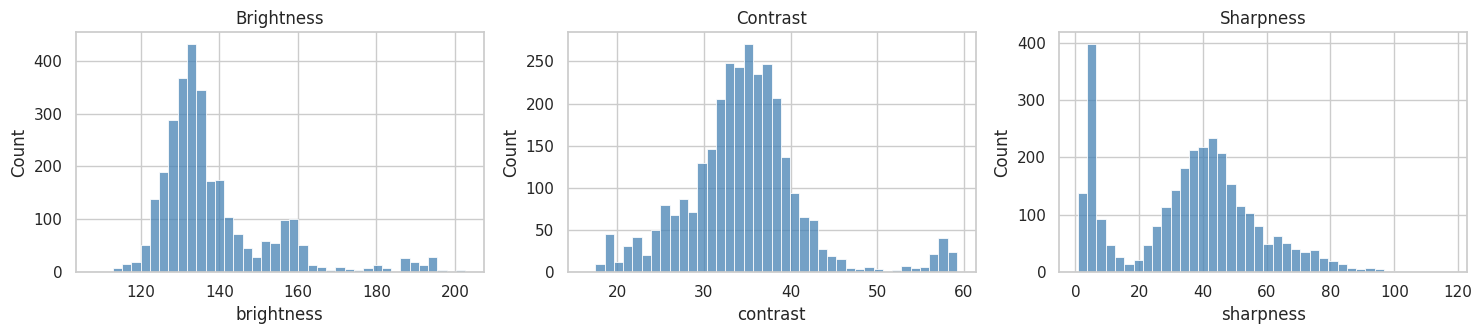

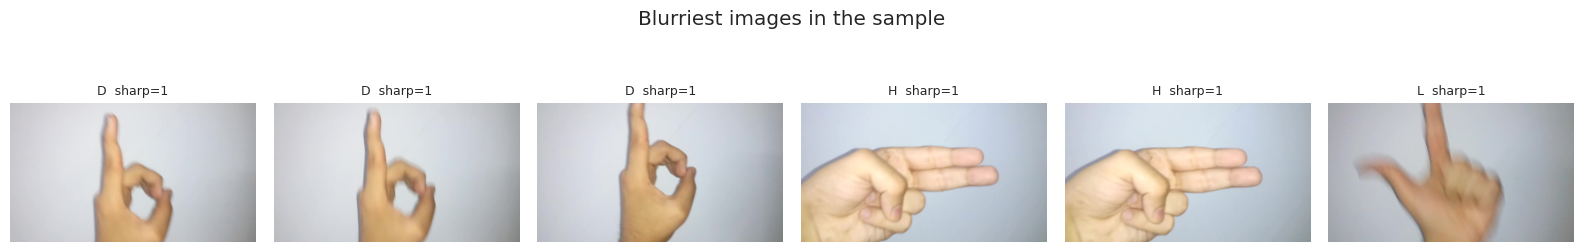

In [8]:
# ---- Image quality on a sample ----
# Three quality numbers for one image (grayscale):
# brightness = mean pixel value, contrast = standard deviation, sharpness = variance of the Laplacian (low = blurry)
def quality(path):
    g = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    return g.mean(), g.std(), cv2.Laplacian(g, cv2.CV_64F).var()

# Use a random sample of up to 3000 images to keep this fast
sample = df.sample(min(3000, len(df)), random_state=SEED).copy()
# Compute the three measures for every sampled image
q = np.array([quality(p) for p in sample["path"]])
sample["brightness"], sample["contrast"], sample["sharpness"] = q[:, 0], q[:, 1], q[:, 2]

# Histograms of brightness, contrast and sharpness across the sample
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for a, c in zip(ax, ["brightness", "contrast", "sharpness"]):
    sns.histplot(sample[c], bins=40, ax=a, color="steelblue"); a.set_title(c.capitalize())
plt.tight_layout(); plt.show()

# Show the 6 blurriest images to see whether they are still usable
blurry = sample.nsmallest(6, "sharpness")
fig, ax = plt.subplots(1, 6, figsize=(16, 3))
for a, (_, r) in zip(ax, blurry.iterrows()):
    a.imshow(Image.open(r["path"]).convert("RGB")); a.set_title(f"{r['label']}  sharp={r['sharpness']:.0f}", fontsize=9); a.axis("off")
plt.suptitle("Blurriest images in the sample"); plt.tight_layout(); plt.show()

## 4. Exploratory Data Analysis

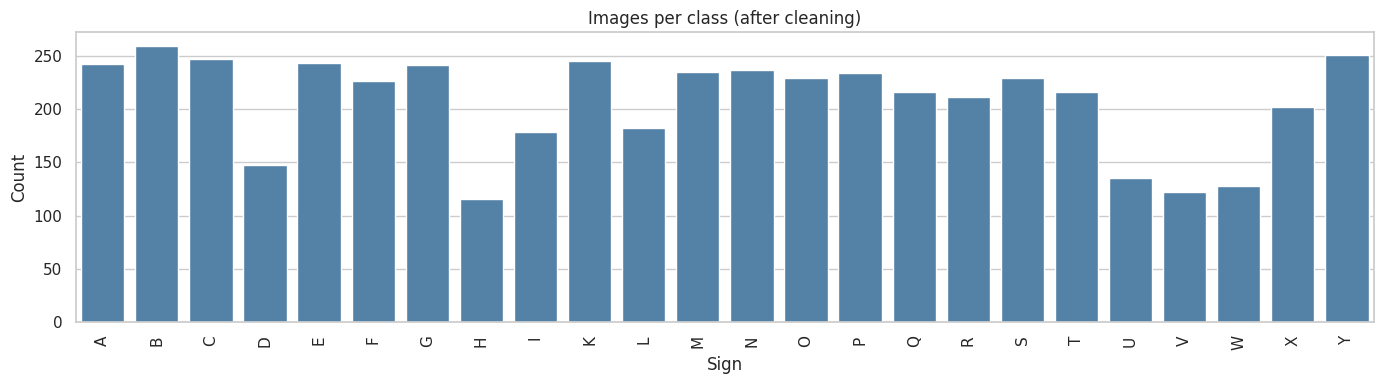

count     24.0
mean     207.1
std       45.4
min      116.0
25%      181.0
50%      227.5
75%      241.2
max      259.0

Imbalance ratio (max/min): 2.23

Colour modes: {'RGB': 4971}
Most common image sizes: {'640x480': 3963, '1920x1088': 830, '1088x1920': 178}


In [9]:
# Class balance: how many images each sign has
counts = df["label"].value_counts().sort_index()
plt.figure(figsize=(14, 4))
sns.barplot(x=counts.index, y=counts.values, color="steelblue")
plt.title("Images per class (after cleaning)"); plt.xlabel("Sign"); plt.ylabel("Count")
plt.xticks(rotation=90); plt.tight_layout(); plt.show()

# Ratio of the biggest to the smallest class (close to 1 = well balanced)
imbalance = counts.max() / counts.min()
print(counts.describe().round(1).to_string())
print(f"\nImbalance ratio (max/min): {imbalance:.2f}")
# Colour modes (RGB, L, ...) and the most common original image sizes
print("\nColour modes:", df["mode"].value_counts().to_dict())
print("Most common image sizes:", df.assign(s=df.width.astype(int).astype(str) + "x" + df.height.astype(int).astype(str))["s"].value_counts().head(5).to_dict())

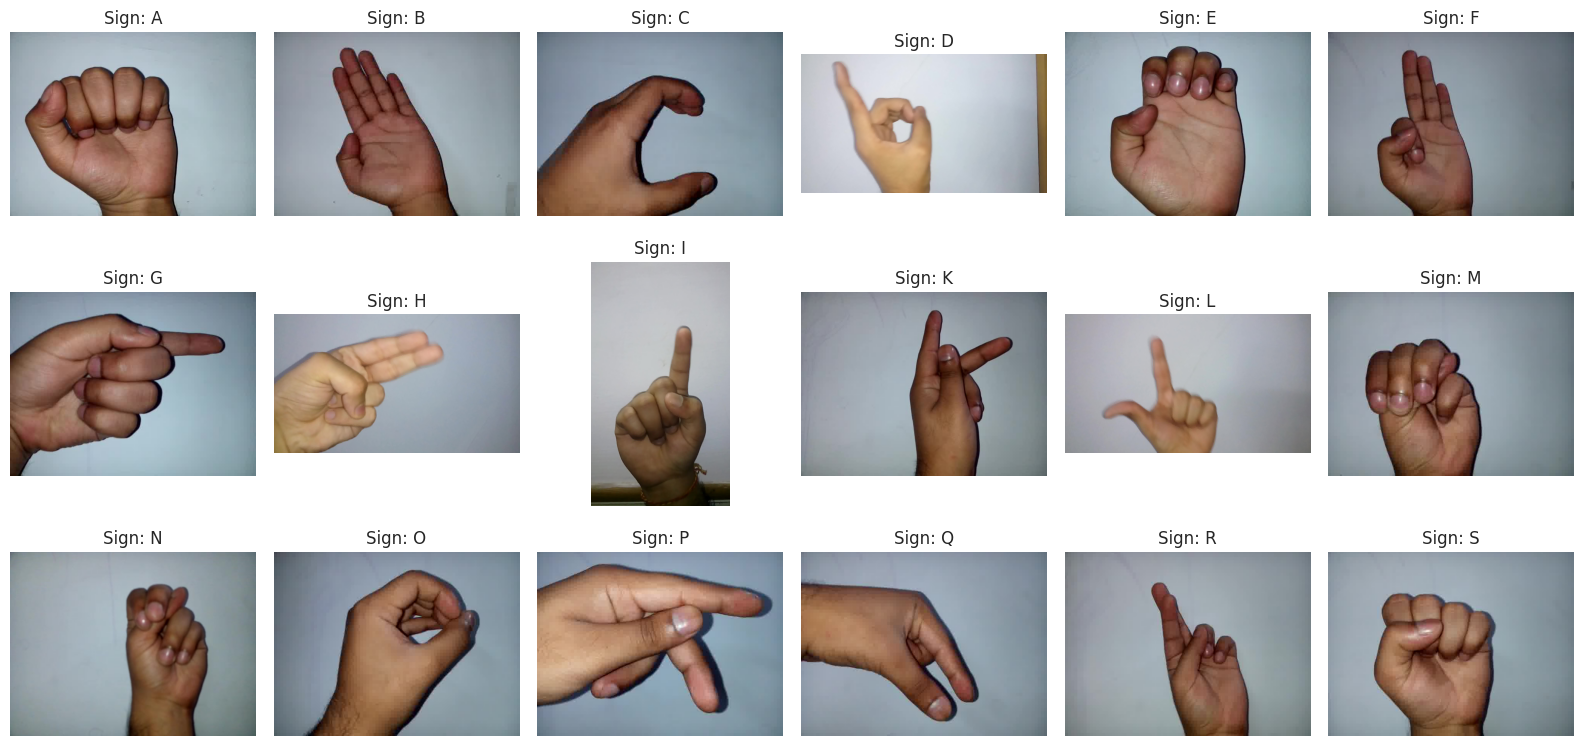

In [10]:
# Show one random example image for each of the first 18 signs
classes_all = sorted(df["label"].unique())
fig, axes = plt.subplots(3, 6, figsize=(16, 8))
for ax, cls in zip(axes.ravel(), classes_all[:18]):
    p = df[df["label"] == cls].sample(1, random_state=SEED)["path"].iloc[0]
    ax.imshow(Image.open(p).convert("RGB")); ax.set_title(f"Sign: {cls}"); ax.axis("off")
plt.tight_layout(); plt.show()

### Mean image per class
The average of many images of one sign shows the typical hand position, framing and any systematic background. A very blurry mean means the signs vary a lot in position.

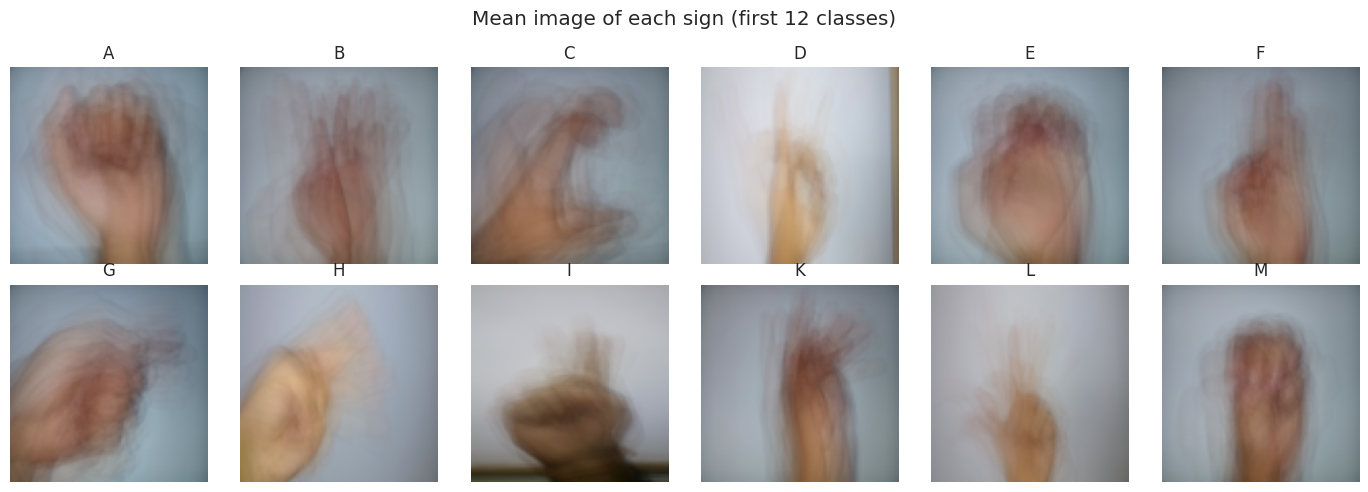

In [11]:
# Mean image per class: averaging many photos of a sign shows its typical hand position and background
def mean_image(paths, size=96, n=40):
    imgs = [np.asarray(Image.open(p).convert("RGB").resize((size, size)), dtype=np.float32) for p in paths[:n]]
    return np.mean(imgs, axis=0).astype(np.uint8)

# Only the first 12 signs are shown to keep the figure small
show = classes_all[:12]
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, cls in zip(axes.ravel(), show):
    ax.imshow(mean_image(df[df["label"] == cls]["path"].tolist())); ax.set_title(cls); ax.axis("off")
plt.suptitle("Mean image of each sign (first 12 classes)"); plt.tight_layout(); plt.show()

## 5. Image Preprocessing (Goal 1)

### 5.1 Classical OpenCV pipeline
Resize, denoise, grayscale and CLAHE contrast enhancement, shown on one image. The deep models below use resize + normalisation + augmentation, but this pipeline documents the cleaning options and suits classical ML.

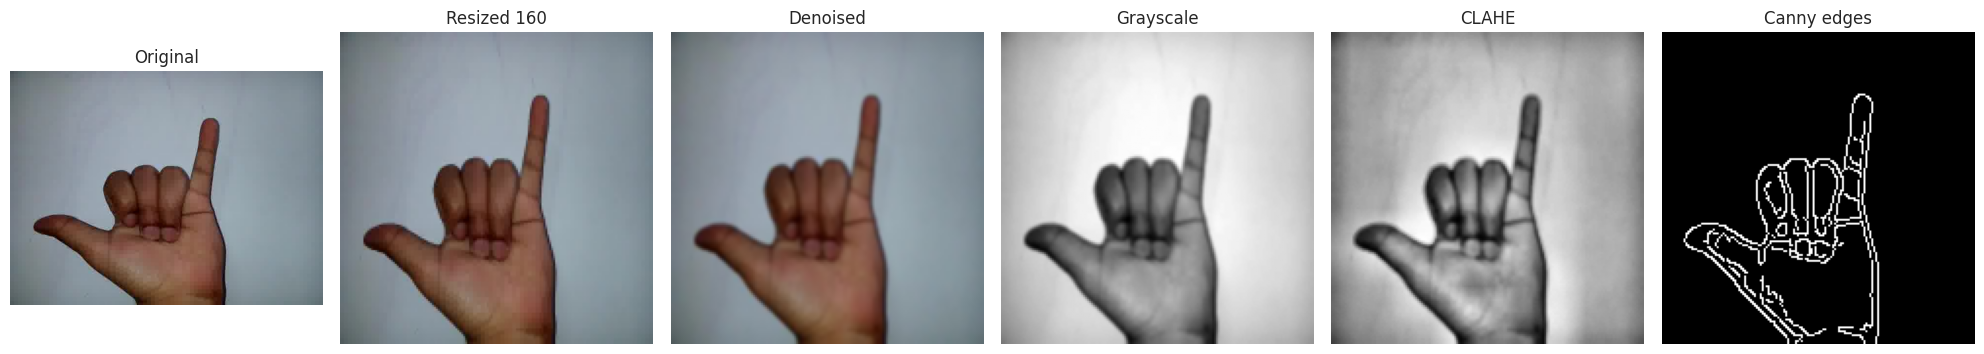

In [12]:
# Classical OpenCV preprocessing demo: shows each cleaning step on one random image
def classical_preprocess(path, size=IMG_SIZE):
    # Read the image and convert from OpenCV's BGR colour order to RGB
    img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    # 1) Resize to the model input size
    resized = cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)
    # 2) Light Gaussian blur removes small noise
    denoised = cv2.GaussianBlur(resized, (3, 3), 0)
    # 3) Convert to grayscale
    gray = cv2.cvtColor(denoised, cv2.COLOR_RGB2GRAY)
    # 4) CLAHE boosts local contrast (helps with uneven lighting)
    enhanced = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray)
    # 5) Canny edge detection outlines the hand shape
    edges = cv2.Canny(enhanced, 80, 160)
    return img, resized, denoised, gray, enhanced, edges

# Run the pipeline on a random image and plot every stage side by side
steps = classical_preprocess(df.sample(1, random_state=7)["path"].iloc[0])
titles = ["Original", f"Resized {IMG_SIZE}", "Denoised", "Grayscale", "CLAHE", "Canny edges"]
fig, axes = plt.subplots(1, 6, figsize=(20, 3.6))
for ax, im, t in zip(axes, steps, titles):
    ax.imshow(im, cmap="gray" if im.ndim == 2 else None); ax.set_title(t); ax.axis("off")
plt.tight_layout(); plt.show()

### 5.2 Leakage-safe stratified split
A plain random split can put two near-identical photos in train and test. We instead use **`StratifiedGroupKFold`** where each *group* is a perceptual-hash cluster. Result:

* every class keeps its proportion in train / validation / test (stratified), and
* images that look identical are never separated across sets (grouped).

Target split is roughly 71% train, 14% validation, 14% test.

In [13]:
# Build numeric labels and a leakage-safe train / validation / test split
# Sorted list of sign names plus lookup tables: name <-> number
class_names = sorted(df["label"].unique())
label2idx = {c: i for i, c in enumerate(class_names)}
idx2label = {i: c for c, i in label2idx.items()}
# Numeric class id used by the models
df["y"] = df["label"].map(label2idx)
NUM_CLASSES = len(class_names)

# Split 1: hold out about 1/7 of the data (~14%) as the TEST set.
# StratifiedGroupKFold keeps class proportions AND keeps look-alike images (same dhash) together
sg1 = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
trainval_idx, test_idx = next(sg1.split(df, df["y"], groups=df["dhash"]))
trainval_df = df.iloc[trainval_idx].reset_index(drop=True)
test_df = df.iloc[test_idx].reset_index(drop=True)

# Split 2: from the remaining data, hold out about 1/6 as the VALIDATION set (used for early stopping and tuning)
sg2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED)
train_idx, val_idx = next(sg2.split(trainval_df, trainval_df["y"], groups=trainval_df["dhash"]))
train_df = trainval_df.iloc[train_idx].reset_index(drop=True)
val_df = trainval_df.iloc[val_idx].reset_index(drop=True)

# Leakage verification: no perceptual-hash overlap between sets
for a, b, n in [(train_df, val_df, "train/val"), (train_df, test_df, "train/test"), (val_df, test_df, "val/test")]:
    print(f"Hash overlap {n:10s}: {len(set(a['dhash']) & set(b['dhash']))}")

# Final size of each set
print(f"\nTrain {len(train_df)} | Val {len(val_df)} | Test {len(test_df)} | Classes {NUM_CLASSES}")
# Images per sign in each set (should be proportional)
split_counts = pd.DataFrame({"train": train_df["label"].value_counts(), "val": val_df["label"].value_counts(),
                             "test": test_df["label"].value_counts()}).fillna(0).astype(int).sort_index()
split_counts.T

Hash overlap train/val : 0
Hash overlap train/test: 0
Hash overlap val/test  : 0

Train 3548 | Val 713 | Test 710 | Classes 24


label,A,B,C,D,E,F,G,H,I,K,...,P,Q,R,S,T,U,V,W,X,Y
train,174,195,187,105,174,170,179,80,130,176,...,162,147,139,167,150,98,96,93,141,172
val,39,33,30,19,33,25,31,20,19,32,...,34,32,43,31,35,18,14,17,32,33
test,29,31,30,23,36,31,31,16,29,37,...,38,37,29,31,31,19,12,18,29,46


### 5.3 Class weights
If some signs have fewer images, the loss is re-weighted so the model does not favour the larger classes.

In [14]:
# Class weights: give rarer signs a larger weight in the loss so the model does not favour the big classes
cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=train_df["y"].values)
class_weight_dict = {i: float(w) for i, w in enumerate(cw)}
# Only apply the weights if the data is noticeably imbalanced (ratio above 1.25)
USE_CLASS_WEIGHTS = imbalance > 1.25
print("Use class weights:", USE_CLASS_WEIGHTS, "| weight range:", round(cw.min(), 2), "to", round(cw.max(), 2))

Use class weights: True | weight range: 0.76 to 1.85



## 6. Input Pipeline and Augmentation
Images are decoded, resized **with padding** (the aspect ratio is kept, so hands are never stretched) and batched with `tf.data`. Labels are one-hot encoded so that **label smoothing** can be used. Pixel scaling happens inside each model.

Augmentation: rotation, zoom, shift, **strong** brightness and contrast changes, and noise. It is deliberately strong: in a first run with mild augmentation the best model scored 99.7% on the test set but only 6.6% on darkened images, so it failed on a real webcam. **Horizontal flips are deliberately excluded**: a mirrored hand shape can be a different, or invalid, sign.

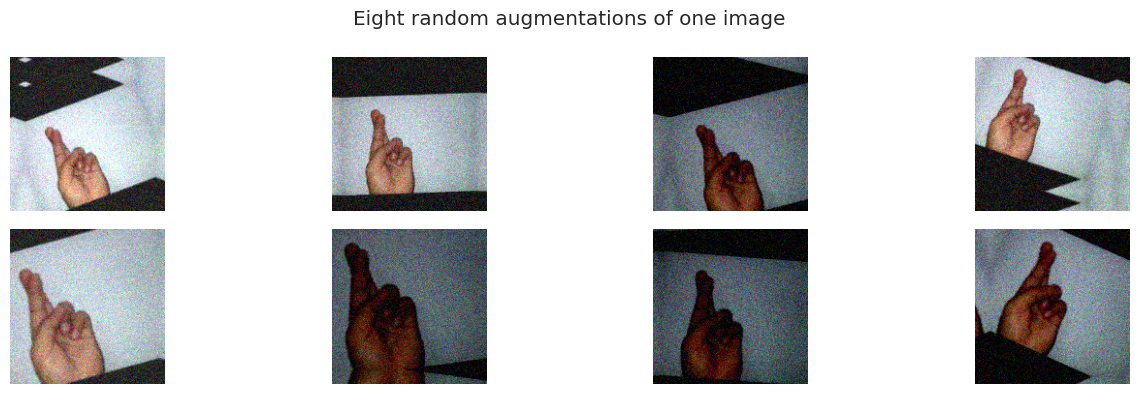

In [15]:
# Input pipeline (tf.data) and data augmentation
AUTOTUNE = tf.data.AUTOTUNE

# Read an image file, decode it to 3 colour channels and resize it to IMG_SIZE x IMG_SIZE
def load_image(path):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    # Resize WITH padding: the aspect ratio is kept, so the hand is never stretched.
    # (The photos come in 640x480, 1920x1088 and 1088x1920, so plain resizing would distort many of them)
    img = tf.image.resize_with_pad(img, IMG_SIZE, IMG_SIZE)
    img.set_shape((IMG_SIZE, IMG_SIZE, 3))
    return img

# Turn a dataframe into a batched tf.data pipeline that yields (image, one-hot label[, weight])
def make_ds(frame, training=False):
    paths = frame["path"].values
    y = frame["y"].values.astype("int32")
    w = np.array([class_weight_dict[i] for i in y], dtype="float32")
    ds = tf.data.Dataset.from_tensor_slices((paths, y, w))
    # Shuffle only the training data (a new order every epoch)
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    # Load the image and one-hot encode its label (needed for label smoothing);
    # add the class weight only for training when weighting is enabled
    def _map(p, yi, wi):
        img, oh = load_image(p), tf.one_hot(yi, NUM_CLASSES)
        return (img, oh, wi) if (training and USE_CLASS_WEIGHTS) else (img, oh)
    # Load in parallel, group into batches and prefetch so the GPU never waits for data
    return ds.map(_map, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

# Build the three datasets
train_ds, val_ds, test_ds = make_ds(train_df, True), make_ds(val_df), make_ds(test_df)   # val/test not shuffled
# True labels of the test set (same order as the unshuffled test_ds)
y_true = test_df["y"].values

# Random changes applied ONLY during training so the model sees varied versions of each image.
# No horizontal flip: a mirrored hand can be a different sign
data_augmentation = keras.Sequential([
    layers.RandomRotation(0.08),
    layers.RandomZoom((-0.3, 0.2)),                        # hand closer to / further from the camera
    layers.RandomTranslation(0.15, 0.15),
    # Strong brightness and contrast changes: the first run collapsed to 6.6% accuracy on darkened images
    layers.RandomBrightness(0.4, value_range=(0, 255)),
    layers.RandomContrast(0.3),
    layers.Rescaling(1 / 255.0),     # to 0-1 so GaussianNoise accepts the value
    layers.GaussianNoise(0.08),      # about 20 on the 0-255 scale (the first run used about 5)
    layers.Rescaling(255.0),         # back to 0-255
], name="augmentation")

# Preview: eight random augmentations of one validation image
batch_imgs = next(iter(val_ds))[0]
plt.figure(figsize=(14, 4))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(np.clip(data_augmentation(batch_imgs[:1], training=True)[0].numpy(), 0, 255).astype("uint8")); plt.axis("off")
plt.suptitle("Eight random augmentations of one image"); plt.tight_layout(); plt.show()

## 7. Modelling (Goal 2)

Shared training recipe:
* **AdamW** optimiser (decoupled weight decay), **label smoothing 0.1**
* **EarlyStopping** on validation accuracy, **ReduceLROnPlateau**, **ModelCheckpoint**
* Transfer models train in two stages: (1) new head with frozen backbone, (2) fine-tune the top layers at a very small learning rate with BatchNorm layers frozen.

In [16]:
# Shared training helpers used by all the models
# Dictionaries that collect each model's metrics, test predictions, training time and history
results, probs_test, train_time, histories = {}, {}, {}, {}

# AdamW optimiser + categorical cross-entropy with label smoothing (0.1) to reduce over-confidence.
# Metrics: accuracy and top-3 accuracy
def compile_model(model, lr):
    model.compile(
        optimizer=keras.optimizers.AdamW(learning_rate=lr, weight_decay=1e-4),
        loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
        metrics=["accuracy", keras.metrics.TopKCategoricalAccuracy(k=min(3, NUM_CLASSES), name="top3")])

# Callbacks: stop when validation accuracy stops improving, lower the learning rate on plateaus, save the best model
def make_callbacks(tag):
    return [keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=4, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
            keras.callbacks.ModelCheckpoint(str(OUT / f"{tag}.keras"), monitor="val_accuracy", save_best_only=True)]

# Plot accuracy and loss curves for training vs validation (can merge several training stages)
def plot_history(hs, title):
    keys = ["accuracy", "val_accuracy", "loss", "val_loss"]
    m = {k: sum([h.history[k] for h in hs], []) for k in keys}
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
    ax[0].plot(m["accuracy"], label="train"); ax[0].plot(m["val_accuracy"], label="val"); ax[0].set_title(f"{title}: accuracy")
    ax[1].plot(m["loss"], label="train"); ax[1].plot(m["val_loss"], label="val"); ax[1].set_title(f"{title}: loss")
    for a in ax: a.set_xlabel("Epoch"); a.legend()
    plt.tight_layout(); plt.show()

### 7.1 Model A: Baseline CNN (from scratch)

Parameters: 1,247,096
Epoch 1/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 40s 230ms/step - accuracy: 0.0877 - loss: 3.0649 - top3: 0.2475 - val_accuracy: 0.0435 - val_loss: 4.0671 - val_top3: 0.0842 - learning_rate: 0.0010
Epoch 2/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 19s 174ms/step - accuracy: 0.1967 - loss: 2.6088 - top3: 0.4543 - val_accuracy: 0.0266 - val_loss: 4.9244 - val_top3: 0.0954 - learning_rate: 0.0010
Epoch 3/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 22s 192ms/step - accuracy: 0.2880 - loss: 2.3396 - top3: 0.5792 - val_accuracy: 0.0589 - val_loss: 3.6349 - val_top3: 0.1431 - learning_rate: 0.0010
Epoch 4/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 20s 184ms/step - accuracy: 0.3506 - loss: 2.1629 - top3: 0.6750 - val_accuracy: 0.0870 - val_loss: 3.7848 - val_top3: 0.1964 - learning_rate: 0.0010
Epoch 5/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 23s 205ms/step - accuracy: 0.4369 - loss: 2.0011 - top3: 0.7579 - val_accuracy: 0.2202 - val_loss: 2.4806 - val_top3: 0.5316 - learning_rate: 0.0010
Epoch 6/20
111/111 ━━━━━━━━━━━━━━

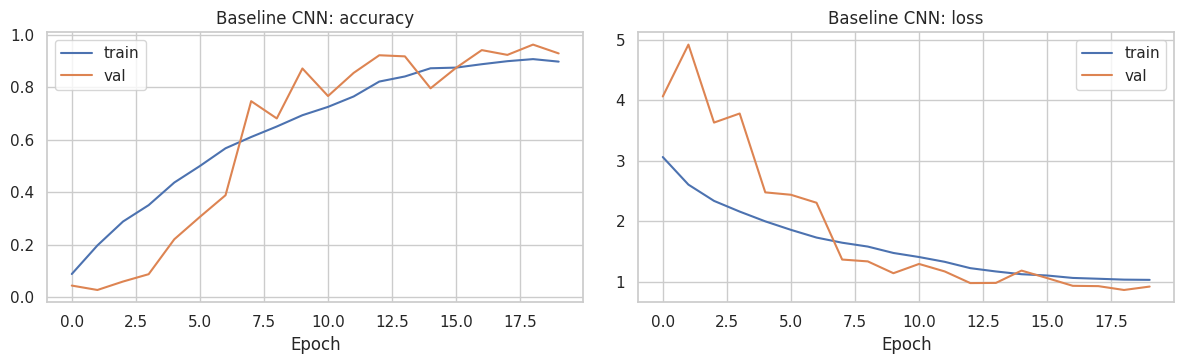

In [17]:
# Model A: baseline CNN trained from scratch (the reference that the other models must beat)
def build_baseline():
    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    # Augmentation layers are part of the model, so they only act during training
    x = data_augmentation(inputs)
    # Scale pixels from 0-255 to 0-1
    x = layers.Rescaling(1. / 255)(x)
    # Four blocks of two conv layers; the number of filters doubles each block.
    # BatchNorm stabilises training, MaxPooling halves the image size, SpatialDropout reduces overfitting
    for f in (32, 64, 128, 256):
        x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x); x = layers.Activation("relu")(x)
        x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x); x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D()(x); x = layers.SpatialDropout2D(0.1)(x)
    # Average each feature map into one number (the layer is named 'gap' and reused for the t-SNE embeddings)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    # Fully connected layer + dropout, then a softmax layer with one output per sign
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    return keras.Model(inputs, layers.Dense(NUM_CLASSES, activation="softmax", name="predictions")(x), name="baseline_cnn")

# Build and compile the model
baseline = build_baseline()
compile_model(baseline, 1e-3)
# Total number of weights
print("Parameters:", f"{baseline.count_params():,}")

# Train the baseline; callbacks stop early and keep the best weights
t0 = time.time()
cb = [keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=5, restore_best_weights=True),
      keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
      keras.callbacks.ModelCheckpoint(str(OUT / "baseline_cnn.keras"), monitor="val_accuracy", save_best_only=True)]
fit_kwargs = {}
h = baseline.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_BASE, callbacks=cb)
# Record training time and history for the final leaderboard
train_time["Baseline CNN"] = time.time() - t0
histories["Baseline CNN"] = [h]
# Plot the learning curves
plot_history([h], "Baseline CNN")

### 7.2 Models B and C: transfer learning (MobileNetV2 and EfficientNetB0)

=== MobileNetV2: stage 1, training the new head ===
Epoch 1/8
111/111 ━━━━━━━━━━━━━━━━━━━━ 16s 94ms/step - accuracy: 0.5287 - loss: 1.9936 - top3: 0.7331 - val_accuracy: 0.1893 - val_loss: 2.9523 - val_top3: 0.3885 - learning_rate: 0.0010
Epoch 2/8
111/111 ━━━━━━━━━━━━━━━━━━━━ 10s 88ms/step - accuracy: 0.7985 - loss: 1.2582 - top3: 0.9487 - val_accuracy: 0.1851 - val_loss: 2.9674 - val_top3: 0.4432 - learning_rate: 0.0010
Epoch 3/8
111/111 ━━━━━━━━━━━━━━━━━━━━ 10s 92ms/step - accuracy: 0.8554 - loss: 1.1325 - top3: 0.9676 - val_accuracy: 0.1978 - val_loss: 2.8078 - val_top3: 0.4755 - learning_rate: 0.0010
Epoch 4/8
111/111 ━━━━━━━━━━━━━━━━━━━━ 8s 74ms/step - accuracy: 0.8799 - loss: 1.0711 - top3: 0.9732 - val_accuracy: 0.2020 - val_loss: 2.8109 - val_top3: 0.4530 - learning_rate: 0.0010
Epoch 5/8
111/111 ━━━━━━━━━━━━━━━━━━━━ 10s 93ms/step - accuracy: 0.9070 - loss: 1.0083 - top3: 0.9828 - val_accuracy: 0.2356 - val_loss: 2.6587 - val_top3: 0.5316 - learning_rate: 0.0010
Epoch 6/8
111/

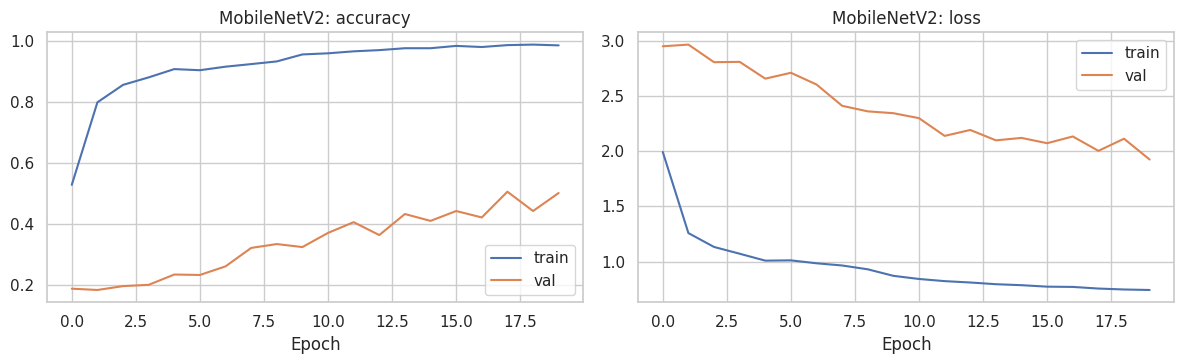

In [20]:
# Transfer learning with two pretrained backbones (ImageNet weights): MobileNetV2 and EfficientNetB0
# Each backbone needs its own pixel scaling: 'pre' is used inside the model, 'pre_np' is the same maths in NumPy (used by Grad-CAM)
BACKBONES = {
    "MobileNetV2":    dict(ctor=keras.applications.MobileNetV2,
                           pre=lambda x: layers.Rescaling(1 / 127.5, offset=-1)(x),   # to [-1, 1]
                           pre_np=lambda x: x / 127.5 - 1.0),
    "EfficientNetB0": dict(ctor=keras.applications.EfficientNetB0,
                           pre=lambda x: x,                                           # has built-in scaling (expects 0-255)
                           pre_np=lambda x: x),
}

def build_backbone_model(name):
    cfg = BACKBONES[name]
    # Load the pretrained network without its original ImageNet classifier
    base = cfg["ctor"](input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights="imagenet")
    # Freeze it at first so the new head can learn without destroying the pretrained features
    base.trainable = False
    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = data_augmentation(inputs)
    x = cfg["pre"](x)
    # training=False keeps the BatchNorm layers in inference mode
    x = base(x, training=False)
    # New classifier head: pooling -> dropout -> softmax over the signs
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax", name="predictions")(x)
    return keras.Model(inputs, out, name=name.lower() + "_isl"), base

# Two-stage training:
# Stage 1 trains only the new head; Stage 2 fine-tunes the top backbone layers with a very small learning rate
def train_backbone(name):
    model, base = build_backbone_model(name)
    t0 = time.time()
    print(f"=== {name}: stage 1, training the new head ===")
    # Stage 1 uses a larger learning rate (1e-3) because only the new head is learning
    compile_model(model, 1e-3)
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD, callbacks=make_callbacks(name + "_head"))

    print(f"=== {name}: stage 2, fine-tuning the top {UNFREEZE_LAYERS} layers ===")
    # Stage 2: unfreeze the backbone, then re-freeze all but the last UNFREEZE_LAYERS layers
    base.trainable = True
    for layer in base.layers[:-UNFREEZE_LAYERS]:
        layer.trainable = False
    # Keep BatchNorm layers frozen: their statistics become unstable with small learning rates
    for layer in base.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    # Very small learning rate so fine-tuning only gently adjusts the pretrained weights
    compile_model(model, 2e-5)
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FT, callbacks=make_callbacks(name + "_ft"))
    train_time[name] = time.time() - t0
    histories[name] = [h1, h2]
    plot_history([h1, h2], name)
    return model, base

# Train MobileNetV2 (a light, fast model)
mobilenet, mobilenet_base = train_backbone("MobileNetV2")

=== EfficientNetB0: stage 1, training the new head ===
Epoch 1/8
111/111 ━━━━━━━━━━━━━━━━━━━━ 24s 116ms/step - accuracy: 0.5660 - loss: 1.9961 - top3: 0.7638 - val_accuracy: 0.4011 - val_loss: 2.1000 - val_top3: 0.7041 - learning_rate: 0.0010
Epoch 2/8
111/111 ━━━━━━━━━━━━━━━━━━━━ 9s 80ms/step - accuracy: 0.8472 - loss: 1.2266 - top3: 0.9665 - val_accuracy: 0.5203 - val_loss: 1.8297 - val_top3: 0.7980 - learning_rate: 0.0010
Epoch 3/8
111/111 ━━━━━━━━━━━━━━━━━━━━ 11s 89ms/step - accuracy: 0.8878 - loss: 1.0834 - top3: 0.9760 - val_accuracy: 0.5610 - val_loss: 1.7302 - val_top3: 0.8513 - learning_rate: 0.0010
Epoch 4/8
111/111 ━━━━━━━━━━━━━━━━━━━━ 11s 97ms/step - accuracy: 0.9076 - loss: 1.0253 - top3: 0.9834 - val_accuracy: 0.5919 - val_loss: 1.6883 - val_top3: 0.8850 - learning_rate: 0.0010
Epoch 5/8
111/111 ━━━━━━━━━━━━━━━━━━━━ 11s 95ms/step - accuracy: 0.9262 - loss: 0.9790 - top3: 0.9876 - val_accuracy: 0.6157 - val_loss: 1.6095 - val_top3: 0.8990 - learning_rate: 0.0010
Epoch 6/8


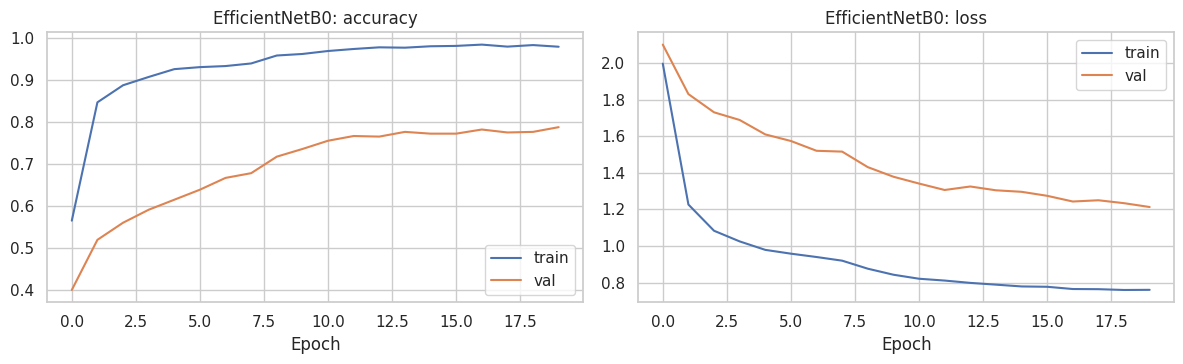

In [21]:
# Train EfficientNetB0 (larger and often more accurate, but slower)
efficientnet, efficientnet_base = train_backbone("EfficientNetB0")

## 8. Evaluation on the Held-out Test Set
The test set was never used for training, tuning or early stopping. Besides accuracy we report **top-3 accuracy**, **macro-F1** (every class counts equally), **Cohen's kappa** and **MCC** (chance-corrected agreement).

In [22]:
# Evaluate all the models on the untouched test set
# Predict on the test set (unless probabilities are supplied) and store six metrics:
# accuracy, top-3 accuracy, macro-F1 (every sign counts equally), weighted-F1, Cohen's kappa and MCC
def evaluate(model, name, probs=None):
    if probs is None:
        probs = model.predict(test_ds, verbose=0)
    y_pred = probs.argmax(1)
    results[name] = dict(
        accuracy=accuracy_score(y_true, y_pred),
        top3=top_k_accuracy_score(y_true, probs, k=min(3, NUM_CLASSES), labels=np.arange(NUM_CLASSES)),
        macro_f1=f1_score(y_true, y_pred, average="macro"),
        weighted_f1=f1_score(y_true, y_pred, average="weighted"),
        kappa=cohen_kappa_score(y_true, y_pred),
        mcc=matthews_corrcoef(y_true, y_pred))
    probs_test[name] = probs
    return results[name]

# All trained models in one place
models = {"Baseline CNN": baseline, "MobileNetV2": mobilenet, "EfficientNetB0": efficientnet}
for n, m in models.items():
    evaluate(m, n)

# Ensemble: average the predicted probabilities of the three models
evaluate(None, "Ensemble (avg of 3)", probs=np.mean([probs_test[n] for n in models], axis=0))
# Show every result as a table
pd.DataFrame(results).T.round(4)

,accuracy,top3,macro_f1,weighted_f1,kappa,mcc
Baseline CNN,0.9606,1.0000,0.9464,0.9597,0.9587,0.9590
MobileNetV2,0.4915,0.7606,0.4424,0.4569,0.4666,0.4834
EfficientNetB0,0.7944,0.9761,0.7906,0.7771,0.7850,0.7962
Ensemble (avg of 3),0.9775,0.9972,0.9723,0.9768,0.9764,0.9766


In [23]:
# Pick the best model by macro-F1 and print its per-sign report
# Best individual model (the ensemble is not a single model, so it is excluded here)
single = {n: results[n]["macro_f1"] for n in models}
best_single_name = max(single, key=single.get)
best_single = models[best_single_name]
# Best result overall, which may be the ensemble
best_overall_name = max(results, key=lambda n: results[n]["macro_f1"])
print("Best single model :", best_single_name)
print("Best overall      :", best_overall_name)

# Use the best overall predictions for the report and charts below
probs = probs_test[best_overall_name]
y_pred = probs.argmax(1)
# Precision, recall and F1 for every sign
print("\n", classification_report(y_true, y_pred, target_names=class_names, digits=3))

Best single model : Baseline CNN
Best overall      : Ensemble (avg of 3)

               precision    recall  f1-score   support

           A      0.935     1.000     0.967        29
           B      1.000     1.000     1.000        31
           C      1.000     1.000     1.000        30
           D      1.000     1.000     1.000        23
           E      1.000     1.000     1.000        36
           F      1.000     1.000     1.000        31
           G      1.000     1.000     1.000        31
           H      1.000     1.000     1.000        16
           I      1.000     1.000     1.000        29
           K      1.000     1.000     1.000        37
           L      1.000     1.000     1.000        25
           M      0.938     1.000     0.968        30
           N      1.000     0.810     0.895        42
           O      1.000     1.000     1.000        30
           P      1.000     1.000     1.000        38
           Q      1.000     1.000     1.000        37
      

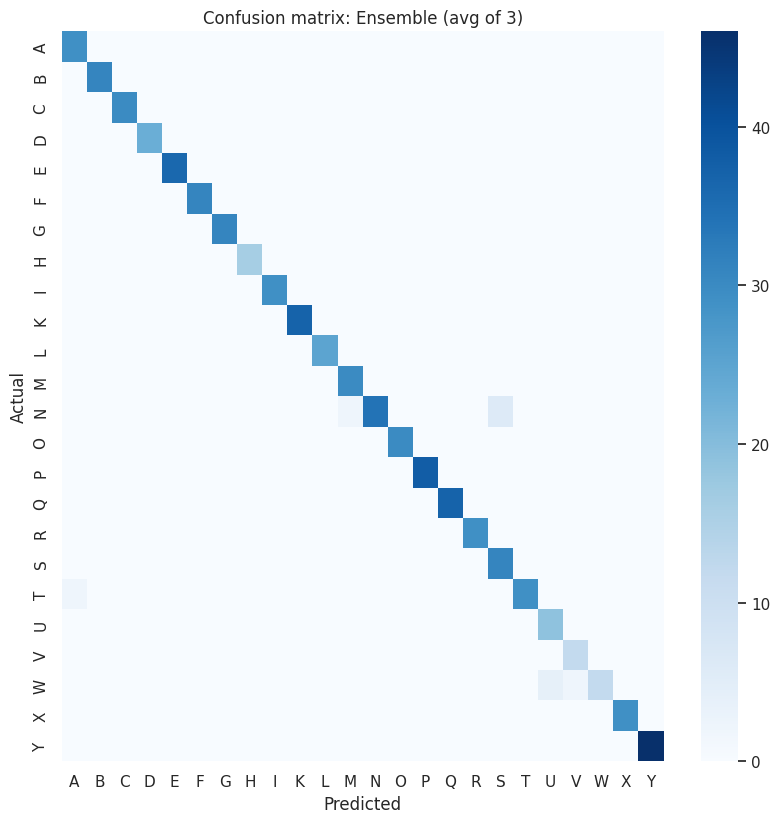

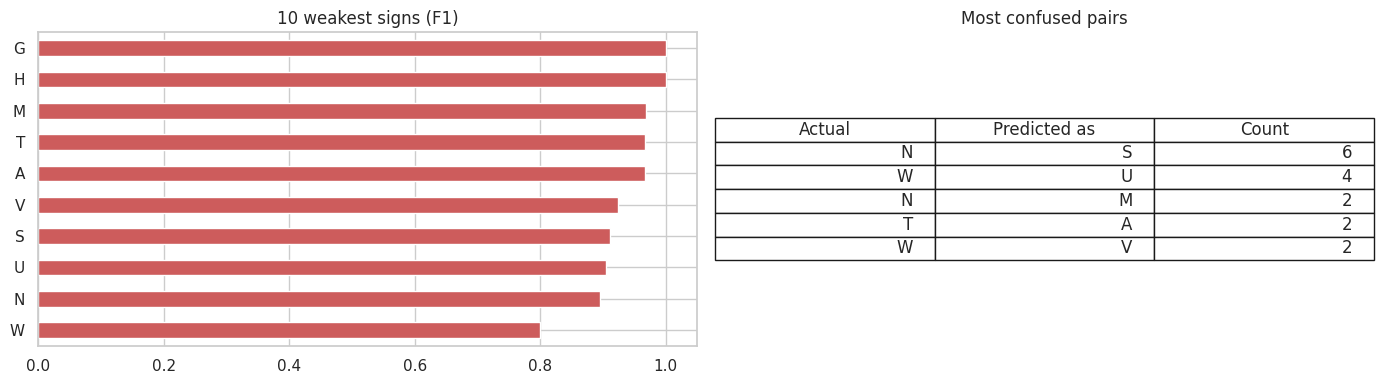

In [24]:
# Confusion matrix, weakest signs and most-confused pairs
# cm[i][j] = how many images of sign i were predicted as sign j
cm = confusion_matrix(y_true, y_pred)
size = max(8, NUM_CLASSES * 0.35)
plt.figure(figsize=(size, size))
sns.heatmap(cm, annot=NUM_CLASSES <= 20, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title(f"Confusion matrix: {best_overall_name}"); plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout(); plt.show()

# F1 score per sign, sorted so the weakest come first
f1s = pd.Series(f1_score(y_true, y_pred, average=None), index=class_names).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
f1s.head(10).plot.barh(ax=ax[0], color="indianred"); ax[0].set_title("10 weakest signs (F1)")
# Remove the diagonal (correct predictions) so only mistakes remain
cm_off = cm.copy(); np.fill_diagonal(cm_off, 0)
# The 10 most frequent (actual -> predicted) mistakes
pairs = sorted([(class_names[i], class_names[j], cm_off[i, j]) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if cm_off[i, j] > 0],
               key=lambda t: -t[2])[:10]
pair_df = pd.DataFrame(pairs, columns=["Actual", "Predicted as", "Count"])
ax[1].axis("off"); ax[1].set_title("Most confused pairs")
if len(pair_df):
    tbl = ax[1].table(cellText=pair_df.values, colLabels=pair_df.columns, loc="center"); tbl.scale(1, 1.4)
plt.tight_layout(); plt.show()

### Error analysis: what does the model get wrong?

Misclassified: 16 of 710 (2.25%)


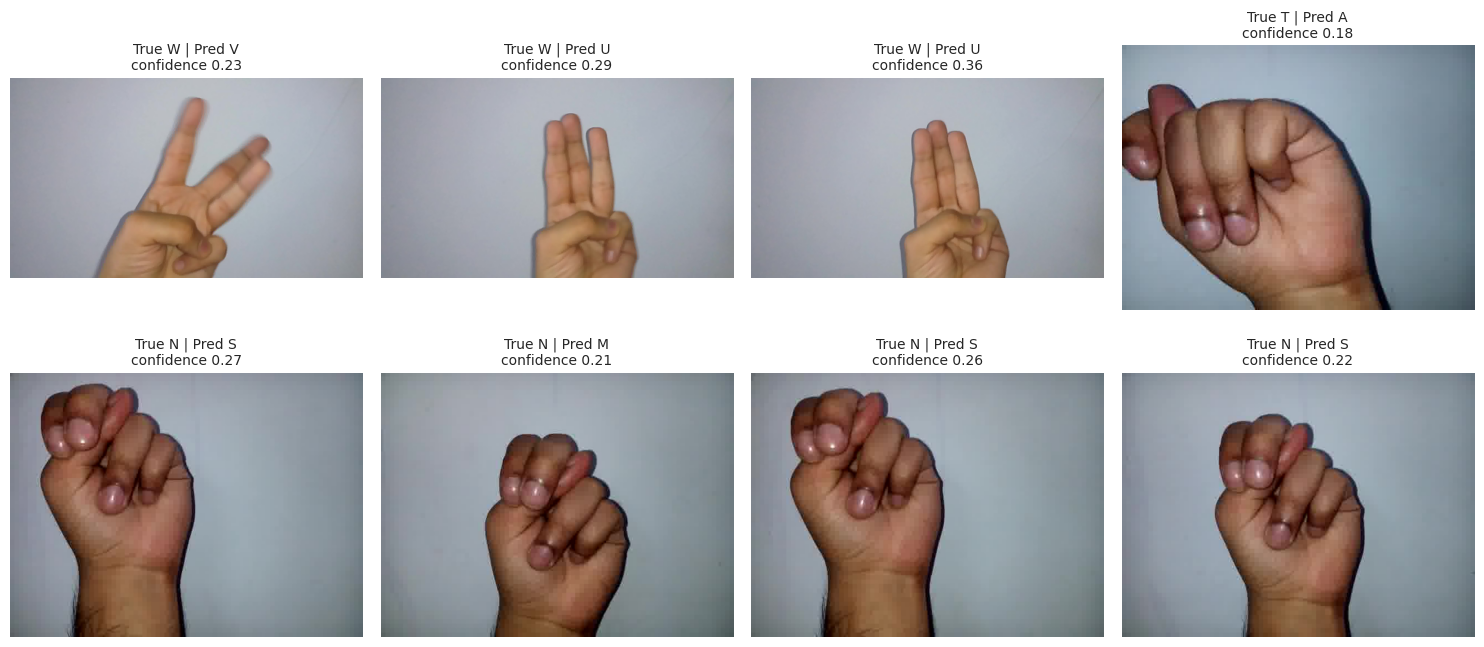

In [25]:
# Error analysis: look at some misclassified test images
# Indices of the test images the model got wrong
wrong = np.where(y_true != y_pred)[0]
print(f"Misclassified: {len(wrong)} of {len(y_true)} ({len(wrong) / len(y_true):.2%})")
if len(wrong):
    # Show up to 8 random mistakes with the true sign, predicted sign and confidence
    pick = np.random.RandomState(SEED).choice(wrong, size=min(8, len(wrong)), replace=False)
    plt.figure(figsize=(15, 7))
    for k, i in enumerate(pick):
        plt.subplot(2, 4, k + 1)
        plt.imshow(Image.open(test_df.iloc[i]["path"]).convert("RGB"))
        plt.title(f"True {idx2label[y_true[i]]} | Pred {idx2label[y_pred[i]]}\nconfidence {probs[i, y_pred[i]]:.2f}", fontsize=10); plt.axis("off")
    plt.tight_layout(); plt.show()

## 9. Reliability: Calibration and Selective Prediction

Accuracy alone is not enough for an assistive tool. We also need the model's **confidence to be honest**.

* **ECE (Expected Calibration Error)**: average gap between confidence and actual accuracy. Lower is better.
* **Temperature scaling**: a single parameter *T* fitted on the *validation* set that rescales confidence without changing predictions.
* **Selective prediction**: only answer when confidence is above a threshold, and ask the user to retry otherwise.

Optimal temperature for Baseline CNN: T = 0.343


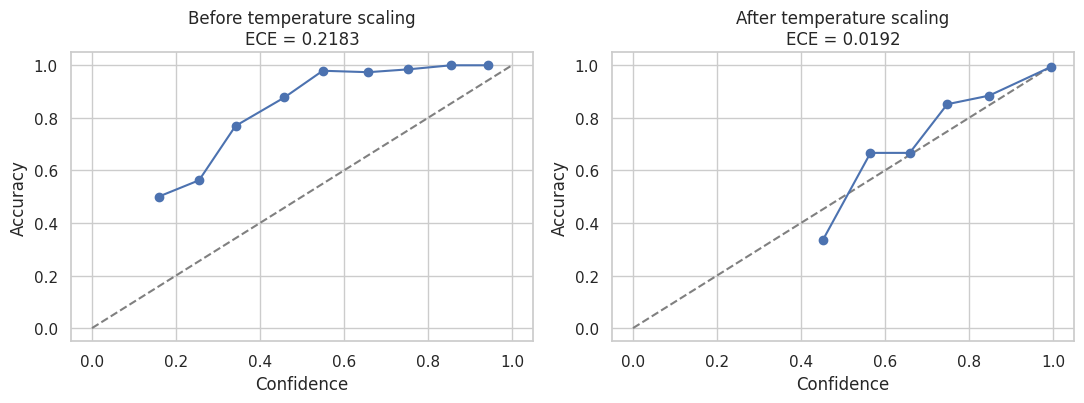

Accuracy unchanged by scaling: True


In [26]:
# Calibration: check whether the model's confidence matches its real accuracy, and fix it with temperature scaling
# Expected Calibration Error: average gap between confidence and accuracy across confidence bins (lower is better)
def ece_score(p, y, n_bins=15):
    conf, pred = p.max(1), p.argmax(1)
    acc = (pred == y).astype(float)
    bins = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.mean() * abs(acc[m].mean() - conf[m].mean())
    return ece

# Reliability diagram: points on the dashed diagonal mean perfectly calibrated
def reliability(p, y, ax, title, n_bins=10):
    conf, acc = p.max(1), (p.argmax(1) == y).astype(float)
    bins = np.linspace(0, 1, n_bins + 1)
    xs, ys = [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): xs.append(conf[m].mean()); ys.append(acc[m].mean())
    ax.plot([0, 1], [0, 1], "--", color="gray"); ax.plot(xs, ys, "o-")
    ax.set_title(f"{title}\nECE = {ece_score(p, y):.4f}"); ax.set_xlabel("Confidence"); ax.set_ylabel("Accuracy")

# Soften (T > 1) or sharpen (T < 1) the probabilities without changing which sign wins
def temperature_scale(p, T):
    z = np.log(np.clip(p, 1e-9, 1)) / T
    z -= z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)

# Fit T on the VALIDATION set of the best single model, then apply to the test set
val_probs = best_single.predict(val_ds, verbose=0)
y_val = val_df["y"].values
# Negative log-likelihood on validation data: the value we minimise to find the best T
nll = lambda T: -np.mean(np.log(np.clip(temperature_scale(val_probs, T)[np.arange(len(y_val)), y_val], 1e-9, 1)))
# Search for the best temperature between 0.05 and 10
T_opt = minimize_scalar(nll, bounds=(0.05, 10), method="bounded").x
print(f"Optimal temperature for {best_single_name}: T = {T_opt:.3f}")

# Test predictions before and after calibration
p_raw = probs_test[best_single_name]
p_cal = temperature_scale(p_raw, T_opt)
# Compare the reliability diagrams side by side
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
reliability(p_raw, y_true, ax[0], "Before temperature scaling")
reliability(p_cal, y_true, ax[1], "After temperature scaling")
plt.tight_layout(); plt.show()
# Scaling must not change the predicted signs, only the confidence
print("Accuracy unchanged by scaling:", accuracy_score(y_true, p_raw.argmax(1)) == accuracy_score(y_true, p_cal.argmax(1)))

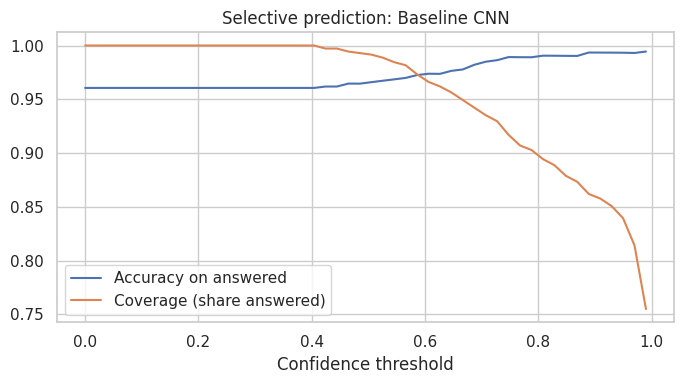

At threshold 0.6: answers 96.6% of images with 97.38% accuracy


In [27]:
# Selective prediction: what happens if the model only answers when it is confident
# Confidence and correctness of every calibrated test prediction
conf = p_cal.max(1); correct = (p_cal.argmax(1) == y_true)
# For each threshold: coverage = share of images answered, sel_acc = accuracy on those answered
thr = np.linspace(0.0, 0.99, 50)
coverage = [(conf >= t).mean() for t in thr]
sel_acc = [correct[conf >= t].mean() if (conf >= t).any() else np.nan for t in thr]

# Plot accuracy and coverage against the confidence threshold
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(thr, sel_acc, label="Accuracy on answered"); ax.plot(thr, coverage, label="Coverage (share answered)")
ax.set_xlabel("Confidence threshold"); ax.set_title(f"Selective prediction: {best_single_name}"); ax.legend()
plt.tight_layout(); plt.show()

# Below this confidence the app says 'uncertain' instead of guessing (also used by the live demo)
REJECT_THRESHOLD = 0.60
# Report coverage and accuracy at the chosen threshold
m = conf >= REJECT_THRESHOLD
print(f"At threshold {REJECT_THRESHOLD}: answers {m.mean():.1%} of images with {correct[m].mean():.2%} accuracy")

## 10. Explainability

### 10.1 Grad-CAM
Grad-CAM highlights the image regions that pushed the model towards its prediction. For a sign-language model we want the heat on the **hands**, not on the background or the person's clothes. If the model relies on the background it will fail on new users.

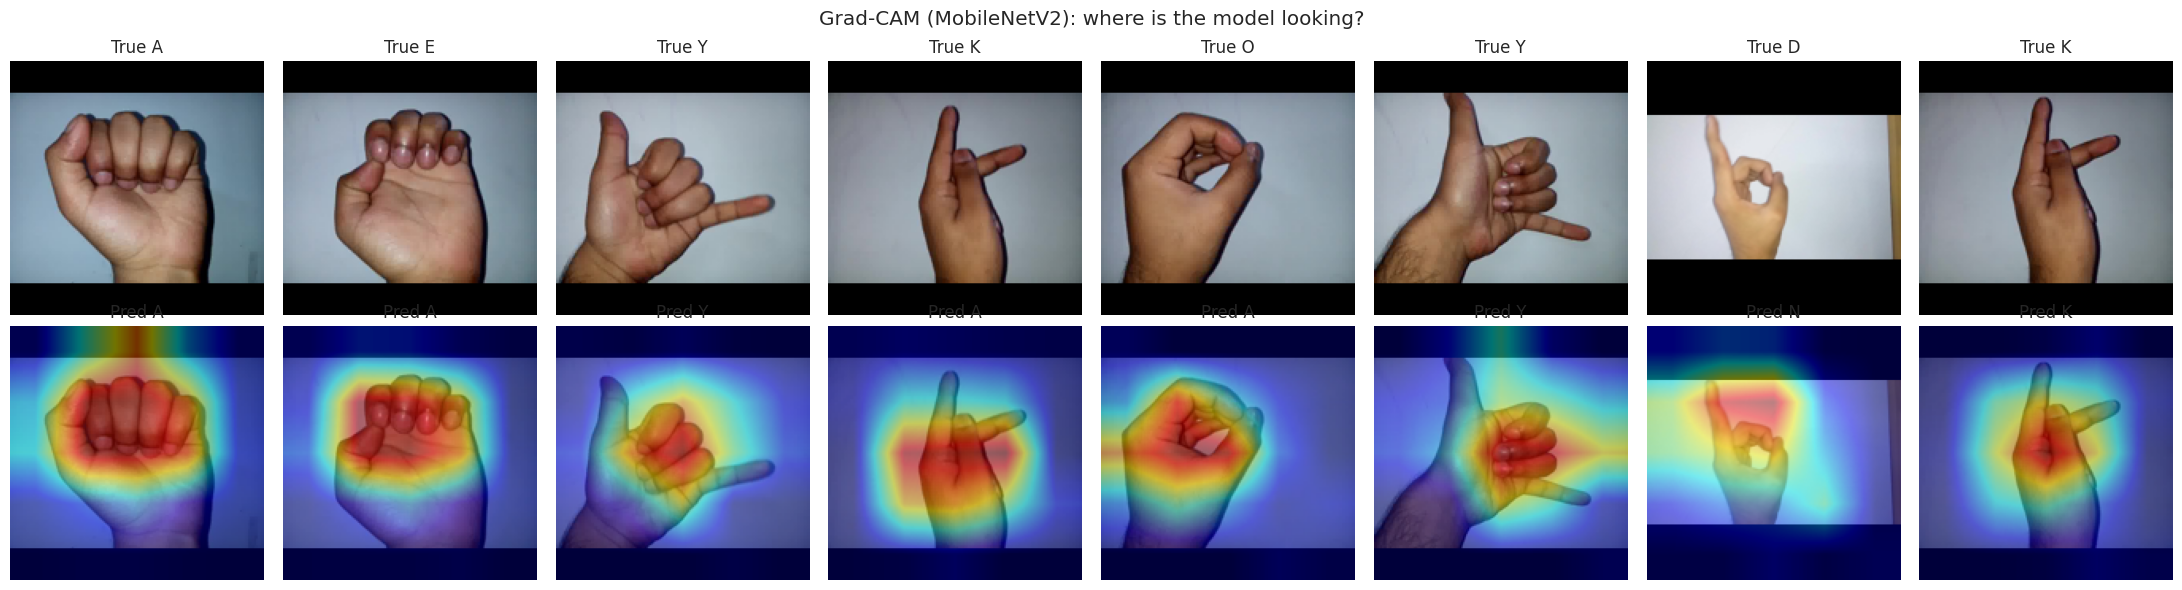

In [28]:
# Grad-CAM: highlight which image regions made the model choose its answer
# Backbone network of each transfer-learning model
BASE_OF = {"MobileNetV2": mobilenet_base, "EfficientNetB0": efficientnet_base}
# Model used for Grad-CAM: the best single model if it has a pretrained backbone, otherwise MobileNetV2
cam_name = best_single_name if best_single_name in BASE_OF else "MobileNetV2"
cam_model, cam_base, cam_pre = models[cam_name], BASE_OF[cam_name], BACKBONES[cam_name]["pre_np"]
# Sub-model that outputs the last convolutional feature maps
feat_model = keras.Model(cam_base.input, cam_base.output)
# The final softmax layer that turns pooled features into sign probabilities
head = cam_model.get_layer("predictions")

# Weight each feature map by how much it increases the score of the chosen sign, then sum them into a heat map
def grad_cam(img_batch, class_idx=None):
    # Apply the same pixel scaling the model uses
    x = tf.convert_to_tensor(cam_pre(img_batch.astype("float32")))
    # Record operations so we can take gradients of the sign score
    with tf.GradientTape() as tape:
        conv = feat_model(x, training=False)
        tape.watch(conv)
        preds = head(tf.reduce_mean(conv, axis=(1, 2)))
        # By default explain the model's own top prediction
        if class_idx is None:
            class_idx = int(tf.argmax(preds[0]))
        score = preds[:, class_idx]
    # Gradient of the sign score with respect to the feature maps
    grads = tape.gradient(score, conv)
    # Importance of each feature map = its average gradient
    w = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    # Weighted sum of the feature maps; ReLU keeps only regions that support the sign
    cam = tf.nn.relu(tf.reduce_sum(w * conv, axis=-1))[0].numpy()
    return cam / (cam.max() + 1e-8), preds[0].numpy()

# Colour the heat map (red = important) and blend it over the original image
def overlay(img_uint8, cam):
    heat = cv2.applyColorMap(np.uint8(255 * cv2.resize(cam, (IMG_SIZE, IMG_SIZE))), cv2.COLORMAP_JET)
    heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB)
    return cv2.addWeighted(img_uint8, 0.55, heat, 0.45, 0)

# Load an image file as a uint8 array of size IMG_SIZE x IMG_SIZE
def load_np(path):
    # Pad (keep the aspect ratio) exactly like the training pipeline does
    return np.asarray(ImageOps.pad(Image.open(path).convert("RGB"), (IMG_SIZE, IMG_SIZE)), dtype=np.uint8)

# Pick 8 random test images and show the original (top row) and the Grad-CAM overlay (bottom row)
idxs = np.random.RandomState(1).choice(len(test_df), 8, replace=False)
fig, axes = plt.subplots(2, 8, figsize=(22, 6))
for k, i in enumerate(idxs):
    im = load_np(test_df.iloc[i]["path"])
    cam, pr = grad_cam(im[None])
    axes[0, k].imshow(im); axes[0, k].axis("off"); axes[0, k].set_title(f"True {test_df.iloc[i]['label']}")
    axes[1, k].imshow(overlay(im, cam)); axes[1, k].axis("off"); axes[1, k].set_title(f"Pred {idx2label[int(pr.argmax())]}")
plt.suptitle(f"Grad-CAM ({cam_name}): where is the model looking?"); plt.tight_layout(); plt.show()

### 10.2 Embedding space (t-SNE)
The penultimate-layer features of the model, projected to 2-D. Well-separated clusters mean the model has learned distinct representations; overlapping clusters match the confusions seen earlier.

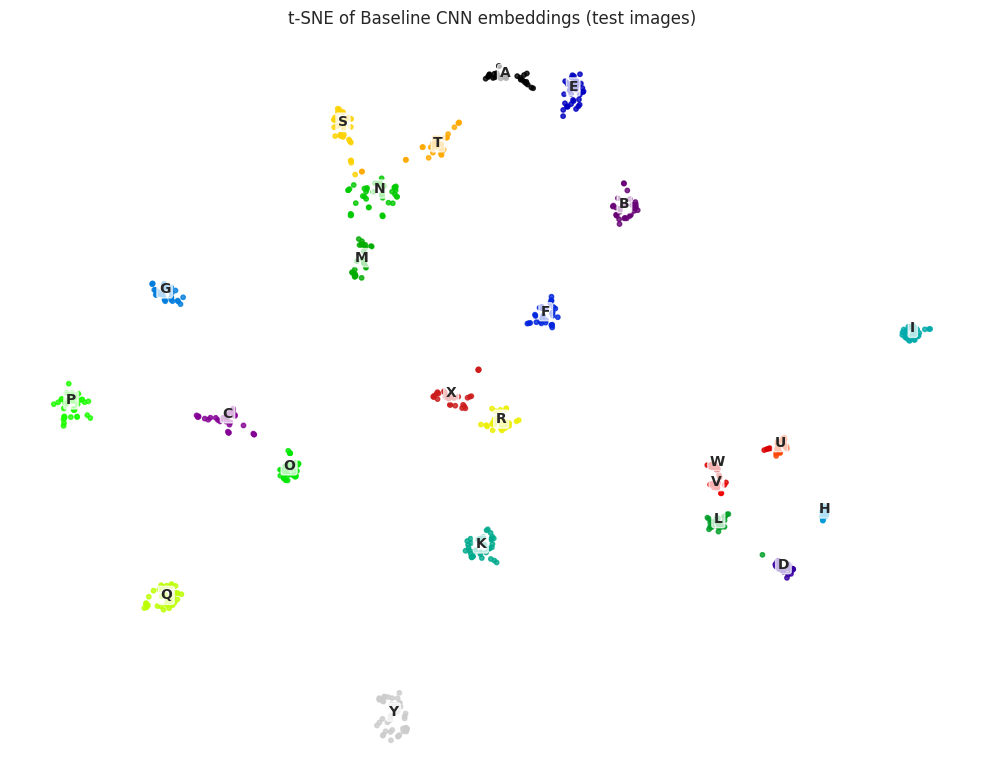

In [29]:
# t-SNE: project the model's internal features to 2-D to see how well the signs separate
# Model that outputs the pooled features (the 'gap' layer) instead of sign probabilities
emb_model = keras.Model(best_single.input, best_single.get_layer("gap").output)
# Use up to 1500 random test images (t-SNE is slow on large sets)
n_emb = min(1500, len(test_df))
emb_idx = np.random.RandomState(SEED).choice(len(test_df), n_emb, replace=False)
sub = test_df.iloc[emb_idx]
imgs = np.stack([load_np(p) for p in sub["path"]]).astype("float32")
# Extract the feature vector of each image
feats = emb_model.predict(imgs, batch_size=64, verbose=0)

# Reduce the features to 2 dimensions
xy = TSNE(n_components=2, perplexity=min(30, n_emb // 4), init="pca", random_state=SEED).fit_transform(feats)
# Scatter plot coloured by true sign; each cluster is labelled with its letter
plt.figure(figsize=(10, 8))
plt.scatter(xy[:, 0], xy[:, 1], c=sub["y"].values, cmap="nipy_spectral", s=10, alpha=0.8)
for c in range(NUM_CLASSES):
    m = sub["y"].values == c
    if m.any():
        cx, cy = np.median(xy[m], axis=0)
        plt.text(cx, cy, idx2label[c], fontsize=10, weight="bold", ha="center", bbox=dict(boxstyle="round,pad=0.15", fc="white", alpha=0.7))
plt.title(f"t-SNE of {best_single_name} embeddings (test images)"); plt.axis("off"); plt.tight_layout(); plt.show()

## 11. Robustness Testing
Real users will not photograph signs under studio conditions. We re-evaluate the best single model, and then every model, on test images that have been artificially degraded. The result is used to choose which model is deployed. A large drop reveals what to fix with more data or stronger augmentation.

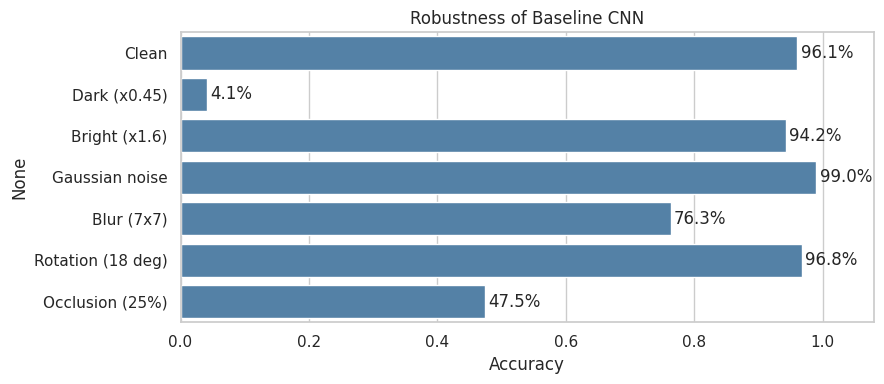

In [30]:
# Robustness test: how much does accuracy drop when images are degraded (dark, noisy, blurred, rotated, partly hidden)?
# Random generator for the noise and the occlusion position
rng = np.random.RandomState(SEED)

# Each function below degrades a batch of images (pixel values 0-255)
def p_dark(x):   return x * 0.45
def p_bright(x): return np.clip(x * 1.6, 0, 255)
def p_noise(x):  return np.clip(x + rng.normal(0, 25, x.shape), 0, 255)
def p_blur(x):   return tf.nn.avg_pool2d(x, 7, 1, "SAME").numpy()
def p_rot(x):    return layers.RandomRotation((0.05, 0.05), fill_mode="nearest")(x, training=True).numpy()
# Occlusion: hide a square covering 25% of the image with grey
def p_occ(x):
    x = x.copy(); s = IMG_SIZE // 2
    r, c = rng.randint(0, IMG_SIZE - s, 2); x[:, r:r + s, c:c + s, :] = 127
    return x

# Test name -> function that creates it ('Clean' = unchanged images)
perturbations = {"Clean": lambda x: x, "Dark (x0.45)": p_dark, "Bright (x1.6)": p_bright, "Gaussian noise": p_noise,
                 "Blur (7x7)": p_blur, "Rotation (18 deg)": p_rot, "Occlusion (25%)": p_occ}

# Accuracy of a model on (up to 25 batches of) test images after applying a degradation
def accuracy_under(model, fn, max_batches=25):
    c = n = 0
    for xb, yb in test_ds.take(max_batches):
        xb = fn(xb.numpy().astype("float32"))
        pred = model.predict(xb, verbose=0).argmax(1)
        c += (pred == yb.numpy().argmax(1)).sum(); n += len(pred)
    return c / n

# Run every test with the best single model
rob = {k: accuracy_under(best_single, fn) for k, fn in perturbations.items()}
rob_s = pd.Series(rob)
# Bar chart: the shorter a bar is compared with 'Clean', the less robust the model
plt.figure(figsize=(9, 4))
sns.barplot(x=rob_s.values, y=rob_s.index, color="steelblue")
for i, v in enumerate(rob_s.values): plt.text(v + 0.005, i, f"{v:.1%}", va="center")
plt.xlim(0, 1.08); plt.xlabel("Accuracy"); plt.title(f"Robustness of {best_single_name}")
plt.tight_layout(); plt.show()

### Robustness of every model
The clean test set cannot tell the models apart (they all score above 94%), so we compare them on degraded images instead. The model with the best **mean accuracy under degradations** is the one deployed in section 13.

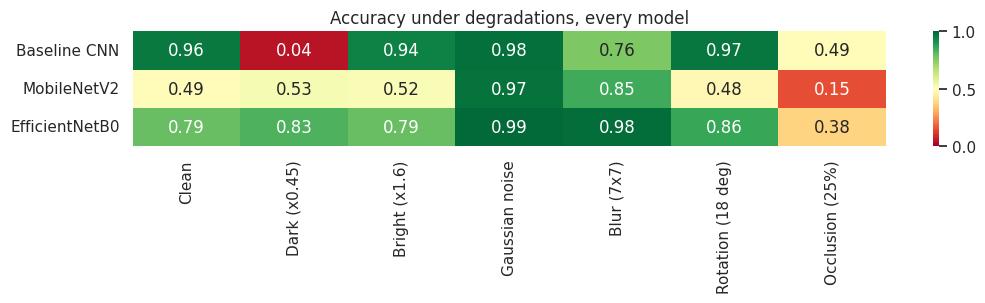

,Clean,Dark (x0.45),Bright (x1.6),Gaussian noise,Blur (7x7),Rotation (18 deg),Occlusion (25%),Mean (without Clean)
Baseline CNN,0.961,0.041,0.942,0.982,0.763,0.968,0.487,0.697
MobileNetV2,0.492,0.525,0.517,0.975,0.851,0.480,0.151,0.583
EfficientNetB0,0.794,0.831,0.794,0.994,0.985,0.863,0.377,0.807


In [31]:
# Robustness of EVERY model (the clean test set alone cannot separate them)
rob_all = {name: {k: accuracy_under(m, fn) for k, fn in perturbations.items()}
           for name, m in models.items()}
rob_table = pd.DataFrame(rob_all).T.round(3)

# Mean accuracy over all degradations (the 'Clean' column is excluded)
rob_table["Mean (without Clean)"] = rob_table.drop(columns="Clean").mean(axis=1).round(3)

# Heat map: rows = models, columns = degradations (green = robust, red = fragile)
plt.figure(figsize=(11, 3.2))
sns.heatmap(rob_table.drop(columns="Mean (without Clean)"), annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1)
plt.title("Accuracy under degradations, every model"); plt.tight_layout(); plt.show()
rob_table

### Your own photos (external test)
The dataset's test set comes from the same photo sessions as the training data, so it is optimistic. This check uses **your own photos**, taken with your phone or webcam. Put them in folders named after the sign, for example `/content/my_test/A/photo1.jpg`, `/content/my_test/B/photo1.jpg`. About 20 photos per sign is enough. If the folder does not exist, the cell just prints a reminder.

In [32]:
# External test set: your own photos, one sub-folder per sign (folder name = sign letter)
EXT_DIR = Path("/content/my_test")
ext_results = {}

if not EXT_DIR.exists():
    print(f"Folder {EXT_DIR} not found. Upload your photos (one sub-folder per sign) to run this check.")
else:
    # Collect the photos and keep only folders whose name is one of the trained signs
    ext = pd.DataFrame([(str(p), p.parent.name) for p in EXT_DIR.rglob("*")
                        if p.is_file() and p.suffix.lower() in IMG_EXT], columns=["path", "label"])
    ext = ext[ext["label"].isin(label2idx)].reset_index(drop=True)

    if len(ext) == 0:
        print("No photos found in folders named after the signs (A, B, C, ...). Check the folder names.")
    else:
        ext["y"] = ext["label"].map(label2idx)
        ext_ds = make_ds(ext)
        print(f"{len(ext)} photos, {ext['label'].nunique()} signs")

        # Accuracy of every model, and of the ensemble, on the photos
        ext_probs = {name: m.predict(ext_ds, verbose=0) for name, m in models.items()}
        for name, p in ext_probs.items():
            ext_results[name] = accuracy_score(ext["y"], p.argmax(1))
        ext_results["Ensemble (avg of 3)"] = accuracy_score(ext["y"], np.mean(list(ext_probs.values()), axis=0).argmax(1))

        print(pd.Series(ext_results, name="accuracy on my photos").round(3).to_string())

Folder /content/my_test not found. Upload your photos (one sub-folder per sign) to run this check.


## 12. Alternative Approach: Hand-Landmark Features (MediaPipe)

Instead of learning from raw pixels, we detect up to **two hands**, take the 21 3-D landmarks per hand, normalise them (wrist at the origin, scaled to unit size) and train classical classifiers. This representation ignores background, clothing and lighting, so it is a strong, lightweight baseline and a good complement to the CNN.

The next cell installs MediaPipe. If the import still fails afterwards, restart the runtime (Runtime -> Restart session) and re-run the notebook from the top. The landmark cells are skipped automatically if MediaPipe is not available.

In [33]:
# Install MediaPipe (needed for the landmark section below and for the 'No hand detected' check in the live demo)
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mediapipe"], check=False)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'mediapipe'], returncode=0)

In [34]:
# Alternative approach: classify using hand landmarks from MediaPipe instead of raw pixels
# Landmarks need the optional 'mediapipe' package; if it is missing this section is skipped
LANDMARKS_OK = False
try:
    import mediapipe as mp
    mp_hands = mp.solutions.hands
    LANDMARKS_OK = True
except Exception as e:
    print("MediaPipe not available, skipping landmark section:", e)

# Use only a subset of images because landmark extraction is slow
LM_TRAIN_PER_CLASS, LM_TEST_PER_CLASS = 120, 60
if QUICK_RUN: LM_TRAIN_PER_CLASS = LM_TEST_PER_CLASS = 20

# Detect up to 2 hands and return a 126-number feature vector (2 hands x 21 points x x,y,z), or None if no hand is found
def extract_landmarks(path, hands):
    img = cv2.imread(path)
    if img is None: return None
    res = hands.process(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    if not res.multi_hand_landmarks: return None
    # Stays zero for a hand that is not visible (for single-hand signs)
    feats = np.zeros(2 * 21 * 3, dtype=np.float32)
    # Order the hands left to right so the features are consistent
    for k, hl in enumerate(sorted(res.multi_hand_landmarks, key=lambda h: h.landmark[0].x)[:2]):
        pts = np.array([[l.x, l.y, l.z] for l in hl.landmark], dtype=np.float32)
        # Move the wrist to the origin (removes the hand's position in the image)
        pts -= pts[0]
        # Scale to unit size (removes the distance from the camera)
        feats[k * 63:(k + 1) * 63] = (pts / (np.abs(pts).max() + 1e-6)).flatten()
    return feats

# Run the detector on every image of a dataframe and keep only the images where a hand was found
def build_lm_set(frame):
    X, y, paths = [], [], []
    with mp_hands.Hands(static_image_mode=True, max_num_hands=2, min_detection_confidence=0.5) as hands:
        for _, r in frame.iterrows():
            f = extract_landmarks(r["path"], hands)
            if f is not None:
                X.append(f); y.append(r["y"]); paths.append(r["path"])
    return np.array(X), np.array(y), paths

# Extract landmarks for the training and test subsets and report how often a hand was detected
if LANDMARKS_OK:
    lm_train_df = train_df.groupby("label").head(LM_TRAIN_PER_CLASS)
    lm_test_df = test_df.groupby("label").head(LM_TEST_PER_CLASS)
    t0 = time.time()
    Xtr, ytr, _ = build_lm_set(lm_train_df)
    Xte, yte, pte = build_lm_set(lm_test_df)
    print(f"Extraction took {time.time() - t0:.0f}s")
    print(f"Hand detected in {len(Xtr) / len(lm_train_df):.1%} of train and {len(Xte) / len(lm_test_df):.1%} of test images")

MediaPipe not available, skipping landmark section: module 'mediapipe' has no attribute 'solutions'


In [35]:
# Train and compare two classical classifiers on the landmark features
if LANDMARKS_OK and len(Xtr) > 50:
    # SVM (with feature scaling) and Random Forest classifiers
    svm = make_pipeline(StandardScaler(), SVC(C=10, gamma="scale"))
    rf = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED)

    # 5-fold cross-validation on the training landmarks gives a more reliable estimate than a single split
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    for name, clf in [("Landmark SVM", svm), ("Landmark RandomForest", rf)]:
        scores = cross_val_score(clf, Xtr, ytr, cv=cv, scoring="accuracy", n_jobs=-1)
        # Fit on all training landmarks, then score on the test landmarks
        clf.fit(Xtr, ytr)
        acc = accuracy_score(yte, clf.predict(Xte))
        print(f"{name:22s} 5-fold CV: {scores.mean():.3f} +/- {scores.std():.3f} | test accuracy (hand detected): {acc:.3f}")
        results[name + " (detected subset)"] = dict(accuracy=acc, macro_f1=f1_score(yte, clf.predict(Xte), average="macro"))

    # Fair comparison: CNN on exactly the same images
    cnn_pred = dict(zip(test_df["path"], y_pred))
    cnn_acc_same = np.mean([cnn_pred[p] == t for p, t in zip(pte, yte)])
    print(f"\n{best_overall_name} on the same {len(yte)} images: {cnn_acc_same:.3f}")

## 13. Deployment

### 13.1 Save the model, class names and metadata

In [36]:
# Save the final model, sign names and settings so the model can be reloaded or deployed

# Choose the model to deploy by ROBUSTNESS, not by clean test score (all models score above 94% there).
# Set FINAL_MODEL_OVERRIDE to a model name such as "EfficientNetB0" to force a particular choice.
FINAL_MODEL_OVERRIDE = None
rob_mean = rob_table["Mean (without Clean)"]
final_name = FINAL_MODEL_OVERRIDE or rob_mean.idxmax()
final_model = models[final_name]
print("Mean accuracy under degradations:\n" + rob_mean.to_string() + f"\n\nDeploying: {final_name}")

# The calibration temperature belongs to ONE model, so fit it again for the chosen model (on validation data)
val_probs_final = final_model.predict(val_ds, verbose=0)
nll_final = lambda T: -np.mean(np.log(np.clip(temperature_scale(val_probs_final, T)[np.arange(len(y_val)), y_val], 1e-9, 1)))
T_opt = minimize_scalar(nll_final, bounds=(0.05, 10), method="bounded").x
print(f"Temperature for {final_name}: T = {T_opt:.3f}")

# Save the model and the list of sign names (in model-output order)
final_model.save(OUT / "isl_recognition_model.keras")
pd.Series(class_names).to_csv(OUT / "isl_class_names.csv", index=False, header=False)

# Settings needed at inference time: image size, calibration temperature and rejection threshold
meta = dict(img_size=IMG_SIZE, num_classes=NUM_CLASSES, model=final_name, temperature=float(T_opt),
            reject_threshold=REJECT_THRESHOLD, test_metrics=results[final_name],
            robustness_mean=float(rob_mean[final_name]))
json.dump(meta, open(OUT / "model_meta.json", "w"), indent=2, default=float)
print("Saved to:", OUT.resolve())
print(json.dumps(meta, indent=2, default=float))


Mean accuracy under degradations:
Baseline CNN      0.697
MobileNetV2       0.583
EfficientNetB0    0.807

Deploying: EfficientNetB0
Temperature for EfficientNetB0: T = 0.521
Saved to: /content/artifacts
{
  "img_size": 160,
  "num_classes": 24,
  "model": "EfficientNetB0",
  "temperature": 0.5209030804125365,
  "reject_threshold": 0.6,
  "test_metrics": {
    "accuracy": 0.7943661971830986,
    "top3": 0.976056338028169,
    "macro_f1": 0.7905749841697803,
    "weighted_f1": 0.7771042330855931,
    "kappa": 0.7850184889076923,
    "mcc": 0.7961960423264897
  },
  "robustness_mean": 0.807
}


### 13.2 Test-time augmentation (TTA) and the inference helper
TTA averages predictions over a few lightly transformed copies of the image, which often adds a small accuracy and stability gain at the cost of a little latency.

No TTA: 0.7583 | With TTA: 0.7979
Actual sign: S


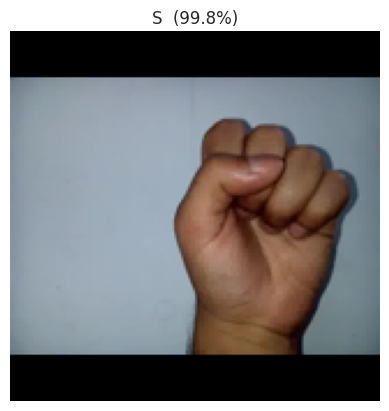

('S',
 [('S', 0.9984305767141269),
  ('A', 0.0006461798639714891),
  ('E', 0.0004720633930030643)])

In [37]:
# Test-time augmentation (TTA) and a single-image prediction helper
# Fixed small rotations (about +/- 11 degrees) used to create extra views of one image
_rot_p = layers.RandomRotation((0.03, 0.03), fill_mode="nearest")
_rot_m = layers.RandomRotation((-0.03, -0.03), fill_mode="nearest")

# Return sign probabilities; with tta=True, average the predictions over 5 slightly altered copies
# (original, two rotations, brighter, darker)
def predict_proba(model, x, tta=False):
    x = x.astype("float32")
    if not tta:
        return model.predict(x, verbose=0)
    views = [x, _rot_p(x, training=True).numpy(), _rot_m(x, training=True).numpy(),
             np.clip(x * 1.15, 0, 255), np.clip(x * 0.85, 0, 255)]
    return np.mean([model.predict(v, verbose=0) for v in views], axis=0)

# Compare accuracy with and without TTA on 15 test batches
def accuracy_tta(model, tta, max_batches=15):
    c = n = 0
    for xb, yb in test_ds.take(max_batches):
        p = predict_proba(model, xb.numpy(), tta)
        c += (p.argmax(1) == yb.numpy().argmax(1)).sum(); n += len(p)
    return c / n

print(f"No TTA: {accuracy_tta(final_model, False):.4f} | With TTA: {accuracy_tta(final_model, True):.4f}")

# Predict the sign in one image file: apply TTA and temperature scaling, answer 'uncertain' if confidence is below REJECT_THRESHOLD
def predict_sign(image_path, model=final_model, top_k=3, tta=True, show=True):
    im = load_np(image_path)
    p = temperature_scale(predict_proba(model, im[None], tta), T_opt)[0]
    top = p.argsort()[::-1][:top_k]
    answer = idx2label[top[0]] if p[top[0]] >= REJECT_THRESHOLD else "uncertain, please retry"
    if show:
        plt.imshow(im); plt.axis("off"); plt.title(f"{answer}  ({p[top[0]]:.1%})"); plt.show()
    return answer, [(idx2label[i], float(p[i])) for i in top]

# Try it on a random test image
demo = test_df.sample(1, random_state=3).iloc[0]
print("Actual sign:", demo["label"])
predict_sign(demo["path"])

### 13.3 Edge deployment: quantised TFLite export and latency benchmark

In [38]:
# Convert the model to quantised TensorFlow Lite (for phones / edge devices) and compare it with the Keras model
try:
    # Convert and apply default (dynamic-range) quantisation to shrink the file
    converter = tf.lite.TFLiteConverter.from_keras_model(final_model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    tflite_bytes = converter.convert()
    (OUT / "isl_model_quant.tflite").write_bytes(tflite_bytes)

    # Load the TFLite model with the TFLite interpreter
    interp = tf.lite.Interpreter(model_path=str(OUT / "isl_model_quant.tflite"))
    interp.allocate_tensors()
    inp, out = interp.get_input_details()[0], interp.get_output_details()[0]

    # Run a single image through the TFLite model
    def tflite_predict(x):
        interp.set_tensor(inp["index"], x.astype("float32")); interp.invoke()
        return interp.get_tensor(out["index"])[0]

    # Compare both models on up to 300 random test images
    n_eval = min(300, len(test_df))
    sub = test_df.sample(n_eval, random_state=SEED)
    X = np.stack([load_np(p) for p in sub["path"]]).astype("float32")
    yy = sub["y"].values

    # Accuracy and time per image for TFLite
    t0 = time.time(); tf_pred = np.array([tflite_predict(X[i:i + 1]).argmax() for i in range(n_eval)]); t_tfl = (time.time() - t0) / n_eval
    # Accuracy and time per image for the Keras model
    t0 = time.time(); kr_pred = np.array([final_model(X[i:i + 1], training=False).numpy().argmax() for i in range(n_eval)]); t_krs = (time.time() - t0) / n_eval

    # File sizes in MB
    size_keras = (OUT / "isl_recognition_model.keras").stat().st_size / 1e6
    size_tfl = (OUT / "isl_model_quant.tflite").stat().st_size / 1e6
    # Table: size, accuracy and speed of both versions
    print(pd.DataFrame({"Keras": [size_keras, kr_pred.__eq__(yy).mean(), t_krs * 1000],
                        "TFLite (quantised)": [size_tfl, tf_pred.__eq__(yy).mean(), t_tfl * 1000]},
                       index=["Size (MB)", f"Accuracy ({n_eval} imgs)", "Latency (ms/image)"]).round(3))
# Export is optional: report the problem instead of stopping the notebook
except Exception as e:
    print("TFLite export skipped:", e)

Saved artifact at '/tmp/tmp3zy7fv9o'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 160, 160, 3), dtype=tf.float32, name='keras_tensor_880')
Output Type:
  TensorSpec(shape=(None, 24), dtype=tf.float32, name=None)
Captures:
  138854554851408: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  138854554856592: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  138850534666512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138850534654416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138850534654224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138850534658832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138850534654608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138850534667088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138850534659024: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138850534654800: TensorSpec(shape=(), dtype=tf.resource, name

### 13.4 Real-time webcam demo (runs inside Colab)
Run the next cell and allow the camera. The video appears with a green box and the predicted sign is shown live. Click **Stop** to end it.

For good results, copy the framing of the dataset photos: a **plain wall** behind you, **good light**, and your **hand close to the camera, filling the frame**, with your chest and face out of view. The cell needs MediaPipe (installed in section 12) so that it can say "No hand detected" instead of guessing.

In [41]:
# Live webcam demo in Colab: the browser sends camera frames to Python, Python predicts and sends the text back to be drawn on the video
import json, time, cv2, numpy as np
from base64 import b64decode
from collections import deque
from IPython.display import display, Javascript
from google.colab.output import eval_js

# ---------------- Settings ----------------
RUN_SECONDS  = 180
SMOOTH       = 5
FLIP_INPUT   = False       # set True if signs are read as mirrored
BOX          = (120, 40, 400)
# Defaults match the training photos (a close-up hand filling the frame); hand detection needs MediaPipe
CROP_TO_HAND = True        # True = crop tightly around the detected hand(s) instead of using the green box
PAD          = 0.25        # extra margin around the hand when CROP_TO_HAND = True

# Make sure the trained model and helper functions exist (run the training cells first)
needed = ["final_model", "T_opt", "REJECT_THRESHOLD", "temperature_scale", "idx2label", "IMG_SIZE", "NUM_CLASSES"]
missing = [n for n in needed if n not in globals()]
if missing:
    raise NameError(f"Run the training cells first. Missing: {missing}")

# ---------------- Hand detector ----------------
# Optional hand detector: lets the demo say 'No hand detected' instead of guessing a sign
try:
    import mediapipe as mp
    hands_det = mp.solutions.hands.Hands(static_image_mode=False, max_num_hands=2,
                                         min_detection_confidence=0.5, min_tracking_confidence=0.5)
    HAND_GATE = True
    print("Hand detection: ON")
except Exception as e:
    HAND_GATE = False
    print("Hand detection: OFF (MediaPipe not available):", e)

# ---------------- Browser side ----------------
# JavaScript that runs in your browser: opens the webcam, draws the green box and the prediction text, and returns one frame per call
JS = r'''
var video, wrap, stream, cv, labelEl, shutdown = false, ready = false;
async function setup() {
  wrap = document.createElement('div');
  wrap.style.cssText = 'position:relative;width:640px;height:480px;background:#000;';
  video = document.createElement('video');
  video.width = 640; video.height = 480; video.muted = true;
  video.setAttribute('playsinline', '');
  video.style.transform = 'scaleX(-1)';
  stream = await navigator.mediaDevices.getUserMedia({video: {width: 640, height: 480}});
  video.srcObject = stream;
  wrap.appendChild(video);
  var box = document.createElement('div');
  box.style.cssText = 'position:absolute;left:120px;top:40px;width:400px;height:400px;border:3px solid #00ff66;box-sizing:border-box;';
  wrap.appendChild(box);
  labelEl = document.createElement('div');
  labelEl.style.cssText = 'position:absolute;left:0;right:0;bottom:0;padding:8px 12px;background:rgba(0,0,0,0.65);color:#00ff66;font:bold 22px monospace;white-space:pre;';
  labelEl.innerText = 'Starting...';
  wrap.appendChild(labelEl);
  var stopBtn = document.createElement('button');
  stopBtn.innerText = 'Stop';
  stopBtn.style.cssText = 'position:absolute;top:8px;right:8px;padding:6px 14px;font-size:16px;';
  stopBtn.onclick = function() { shutdown = true; };
  wrap.appendChild(stopBtn);
  document.body.appendChild(wrap);
  await video.play();
  cv = document.createElement('canvas'); cv.width = 640; cv.height = 480;
  google.colab.output.setIframeHeight(520, true);
  ready = true;
}
function stopCamera() {
  if (stream) { stream.getTracks().forEach(function(t) { t.stop(); }); }
  if (wrap) { wrap.remove(); }
  ready = false; shutdown = false;
}
async function nextFrame(text) {
  if (!ready) { await setup(); }
  if (shutdown) { stopCamera(); return ''; }
  labelEl.innerText = text;
  cv.getContext('2d').drawImage(video, 0, 0, 640, 480);
  return cv.toDataURL('image/jpeg', 0.7);
}
'''
# Inject the JavaScript into the page
display(Javascript(JS))

# ---------------- Python side ----------------
# Position and size of the green square (the region sent to the model)
x0, y0, s = BOX
# The last SMOOTH predictions, used for majority voting to avoid flicker
history = deque(maxlen=SMOOTH)
# Text shown at the bottom of the video
label_text = "Show your hand inside the green box"
# Timers for the run length and the FPS counter
t_start, frames, t_fps, fps = time.time(), 0, time.time(), 0.0

# Main loop: runs until you click Stop or RUN_SECONDS has passed
try:
    while time.time() - t_start < RUN_SECONDS:
        # Ask the browser for the next frame (and send it the latest label text)
        data = eval_js("nextFrame(%s)" % json.dumps(label_text))
        # An empty reply means the Stop button was clicked
        if not data:
            break

        # Decode the JPEG frame sent by the browser
        frame = cv2.imdecode(np.frombuffer(b64decode(data.split(",")[1]), np.uint8), cv2.IMREAD_COLOR)
        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        H, W = rgb.shape[:2]

        # ---- 1. Is there a hand? ----
        hand_found, crop = True, rgb[y0:y0 + s, x0:x0 + s]
        # Look for hands in the full frame
        if HAND_GATE:
            res = hands_det.process(rgb)
            hand_found = bool(res.multi_hand_landmarks)
            # Optionally crop tightly around the detected hand(s) instead of using the green box
            if hand_found and CROP_TO_HAND:
                pts = np.array([[l.x * W, l.y * H] for hl in res.multi_hand_landmarks for l in hl.landmark])
                cx, cy = (pts.min(0) + pts.max(0)) / 2
                side = int(min(max((pts.max(0) - pts.min(0)).max() * (1 + PAD), 120), min(W, H)))
                x1 = int(np.clip(cx - side / 2, 0, W - side)); y1 = int(np.clip(cy - side / 2, 0, H - side))
                crop = rgb[y1:y1 + side, x1:x1 + side]

        # Update the FPS counter once per second
        frames += 1
        if time.time() - t_fps >= 1.0:
            fps, frames, t_fps = frames / (time.time() - t_fps), 0, time.time()

        # No hand: skip the prediction, clear the vote history and tell the user
        if not hand_found:
            history.clear()
            label_text = f"No hand detected\nShow your hand inside the green box\n{fps:.1f} FPS"
            continue

        # ---- 2. Predict ----
        # Optionally mirror the image if signs are being read as mirrored
        if FLIP_INPUT:
            crop = cv2.flip(crop, 1)
        # Resize to the model input size
        roi = cv2.resize(crop, (IMG_SIZE, IMG_SIZE))
        # Predict with the model and calibrate the probabilities
        p = temperature_scale(np.array(final_model(roi[None].astype("float32"), training=False)), T_opt)[0]
        # The three most likely signs
        top = p.argsort()[::-1][:3]
        # Remember this prediction (or -1 if the confidence is too low)
        history.append(int(top[0]) if p[top[0]] >= REJECT_THRESHOLD else -1)
        # Majority vote over the last few frames gives a steadier answer
        vote = max(set(history), key=list(history).count)

        # Build the text overlay: main answer, top-3 list and FPS
        head = f"SIGN: {idx2label[vote]}   {p[top[0]]:.0%}" if vote >= 0 else f"Not sure (guess {idx2label[int(top[0])]} {p[top[0]]:.0%})"
        others = "   ".join(f"{idx2label[int(i)]} {p[i]:.0%}" for i in top)
        label_text = f"{head}\nTop 3: {others}\n{fps:.1f} FPS"
# Always stop the camera, even if an error happened
finally:
    try:
        eval_js("stopCamera()")
    except Exception:
        pass
    print("Camera stopped.")

Hand detection: OFF (MediaPipe not available): module 'mediapipe' has no attribute 'solutions'


<IPython.core.display.Javascript object>

Camera stopped.


### 13.5 Gradio web app
Writes a ready-to-run `app.py` that serves the saved model in the browser (`pip install gradio`, then `python app.py`).

In [42]:
# Write a ready-to-run Gradio web app (app.py) that serves the saved model in the browser
# The app's code is stored as text and saved to app.py (no comments inside the text, so the file stays exactly the same)
app_code = '''import json, numpy as np, gradio as gr, tensorflow as tf
from PIL import Image, ImageOps
meta = json.load(open("artifacts/model_meta.json"))
classes = [l.strip() for l in open("artifacts/isl_class_names.csv")]
model = tf.keras.models.load_model("artifacts/isl_recognition_model.keras")
S, T = meta["img_size"], meta["temperature"]

def predict(img):
    x = np.asarray(ImageOps.pad(Image.fromarray(img).convert("RGB"), (S, S)), dtype="float32")[None]
    p = model.predict(x, verbose=0)[0]
    z = np.log(np.clip(p, 1e-9, 1)) / T; z -= z.max(); p = np.exp(z) / np.exp(z).sum()
    return {classes[i]: float(p[i]) for i in np.argsort(p)[::-1][:5]}

gr.Interface(predict, gr.Image(), gr.Label(num_top_classes=5),
             title="Indian Sign Language Recognition").launch()
'''
# Run it later with:  pip install gradio   then   python app.py
Path("app.py").write_text(app_code)
print("Wrote app.py")

Wrote app.py


## 14. Leaderboard, Model Card and Conclusion

In [43]:
# Leaderboard: one table comparing every approach
# Start from the collected metrics
board = pd.DataFrame(results).T
# Add model size in millions of parameters (landmark models are not Keras models, so they get NaN)
board["params (M)"] = [models[n].count_params() / 1e6 if n in models else np.nan for n in board.index]
# Add training time in minutes
board["train time (min)"] = [train_time.get(n, np.nan) / 60 for n in board.index]
# Mean accuracy under degradations (section 11) and accuracy on your own photos (NaN if that check was not run)
board["robustness (mean)"] = [rob_table["Mean (without Clean)"].get(n, np.nan) for n in board.index]
board["my photos accuracy"] = [ext_results.get(n, np.nan) for n in board.index]
# Rank by macro-F1 (best first)
board = board.sort_values("macro_f1", ascending=False)
# Save as CSV and display the table
board.round(4).to_csv(OUT / "leaderboard.csv")
board.round(4)

,accuracy,top3,macro_f1,weighted_f1,kappa,mcc,params (M),train time (min),robustness (mean),my photos accuracy
Ensemble (avg of 3),0.9775,0.9972,0.9723,0.9768,0.9764,0.9766,NaN,NaN,NaN,NaN
Baseline CNN,0.9606,1.0000,0.9464,0.9597,0.9587,0.9590,1.2471,8.8190,0.697,NaN
EfficientNetB0,0.7944,0.9761,0.7906,0.7771,0.7850,0.7962,4.0803,4.8443,0.807,NaN
MobileNetV2,0.4915,0.7606,0.4424,0.4569,0.4666,0.4834,2.2887,3.5311,0.583,NaN


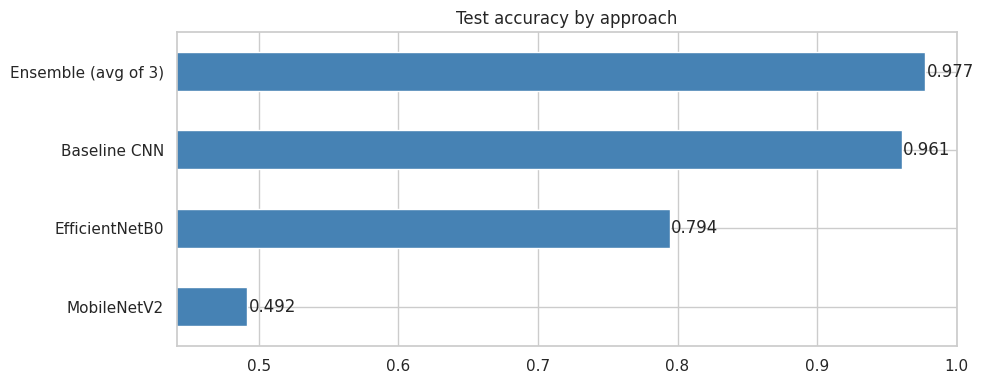

In [44]:
# Bar chart of test accuracy for every approach
fig, ax = plt.subplots(figsize=(10, 4))
board["accuracy"].dropna().sort_values().plot.barh(ax=ax, color="steelblue")
# Zoom the axis to the range of scores so small differences are visible
ax.set_xlim(max(0, board["accuracy"].min() - 0.05), 1.0); ax.set_title("Test accuracy by approach")
for i, v in enumerate(board["accuracy"].dropna().sort_values().values): ax.text(v + 0.001, i, f"{v:.3f}", va="center")
plt.tight_layout(); plt.show()

### Model card

| Item | Detail |
|---|---|
| **Task** | Multi-class classification of static, one-handed sign letters (24 classes: A to Y without J and Z) from a single image |
| **Input** | RGB image, padded to keep its aspect ratio and resized to 160 x 160 |
| **Output** | Probability over all sign classes, with a confidence-based "uncertain" option |
| **Training data** | PRAICP-1000-IndiSignLang (DataMites), 4,971 images after removing corrupted and duplicate files; close-up photos on a plain background |
| **Validation** | Stratified, group-aware split with verified zero hash overlap between train / val / test |
| **Models compared** | Baseline CNN, MobileNetV2, EfficientNetB0, probability ensemble, landmark SVM / RF |
| **Reported metrics** | Accuracy, top-3, macro-F1, kappa, MCC, ECE, robustness under perturbations |
| **Intended use** | Learning aid and prototype for sign-to-text accessibility tools |
| **Out of scope** | Safety-critical or legal communication; dynamic (motion) signs such as J and Z; two-handed signs; full sentences |

### Key findings
Fill these in from your own run (the numbers appear in the tables and plots above):
1. Best model and its test accuracy / macro-F1, and whether the ensemble improved on it.
2. Which signs are weakest and which pairs are confused (confusion matrix and F1 plot), and whether they look visually similar.
3. Whether Grad-CAM focuses on the hands, or on the background.
4. How much accuracy drops under the worst perturbation in the robustness test.
5. Calibration: ECE before and after temperature scaling.
6. Landmark approach versus CNN on the same images.
7. TFLite size reduction and latency versus the Keras model.
8. Accuracy on your own photos versus the dataset's test set, and which model was deployed (chosen by robustness).

### What the first run taught us
In the first run the best single model, the baseline CNN, scored 99.7% on the dataset's test set but only 6.6% on darkened images, 51% on blurred images and 60% on noisy images, and it gave wrong letters on a live webcam. The test set looks too much like the training photos to expose this. We therefore (1) made the augmentation much stronger, (2) kept the aspect ratio when resizing, (3) compared every model on degraded images and on your own photos, and (4) deployed the most robust model instead of the one with the highest clean score.

### Limitations
* Single static images only: motion-based signs, words and sentences need video models.
* The dataset has no J or Z (they need motion) and contains one-handed letters only; official ISL fingerspelling uses two hands for many letters, so this covers a one-handed subset.
* Accuracy depends on the signers, backgrounds and cameras in the dataset; unseen users or scenes will usually score lower than the test set.
* The test set comes from the same collection as training, so real-world accuracy should be confirmed on fresh photos.

### Future work
* Add video support (CNN-LSTM, 3-D CNN or a landmark-sequence transformer) for dynamic signs and sentences.
* Fuse CNN and landmark predictions (late fusion) for background-robust accuracy.
* Collect more diverse signers, backgrounds and lighting; track fairness per signer and skin tone.
* Quantisation-aware training and deployment as a mobile app (TFLite / Core ML).
* Pair with speech synthesis for a two-way communication tool.